# Deep Reinforcement Learning for Multi-Node Smart-Grid Power Balancing

**Project goal.** Keep a three-node power grid (A = city, B = suburb, C = industrial) as close to
zero net imbalance as possible by routing power between the nodes, using deep RL controllers that
are trained on a synthetic but physically-motivated grid simulator.

The notebook contains **two complementary control paradigms** plus a supervised pre-training stage:

| Stage | Component | Description |
|---|---|---|
| 1 | `generate_complex_data` | Synthetic hourly grid simulator: diurnal load/generation cycles, a 3-state Markov weather regime, momentum (random-walk) noise, demand spikes and generator outages. |
| 2 | `train_forecaster` | Supervised LSTM that forecasts next-hour net imbalance for all three nodes. Its `feature_extractor` layer is reused as a frozen backbone for transfer learning. |
| 3 | `FastEnv` + `TransformerAgent` | **Centralized** control: one Transformer-DQN observes the whole grid and picks one of 7 discrete routing actions. |
| 3b | `TransferAgent` | Same discrete task, but the state encoder is the **frozen forecaster backbone** (transfer learning) — used as a comparison model. |
| 4 | `PettingZooGridEnv` + `LocalSubstationAgent` | **Decentralized** control: three communicating PPO actor-critic agents, one per substation, each with continuous delta-control over one transmission line. |

**How to run.** Execute top-to-bottom in a fresh kernel. Every cell only depends on cells above it.
All randomness is seeded from a single `SEED`, and training lengths are exposed as constants in the
configuration cell (they can be shortened through environment variables for a smoke test without
editing the notebook).

In [1]:
# Dependencies. PettingZoo supplies the ParallelEnv API used by the multi-agent section (Part 4).
# Moved to the top of the notebook so that a fresh kernel can run straight through; `-q` keeps the
# log short and pip is a no-op when the package is already present.
%pip install -q pettingzoo

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration and reproducibility

Everything that controls the experiment lives here: the master random seed, the artifact directory
(models and figures are written next to the notebook instead of into an implicit working directory),
and the training budgets.

Original notebook had **no seeding at all**, so every run produced different data, different weights
and different metrics. `set_global_seeds` seeds Python, NumPy and TensorFlow, and every dataset is
generated from its own derived seed so results are reproducible regardless of execution order.

In [2]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

# --- Reproducibility -----------------------------------------------------------------------
SEED = 42

def set_global_seeds(seed=SEED):
    """Seed every RNG that influences the results (Python, NumPy, TensorFlow/Keras)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:                                   # Keras 3 convenience helper, ignore on older versions
        tf.keras.utils.set_random_seed(seed)
    except Exception:
        pass

set_global_seeds()

# --- Paths ---------------------------------------------------------------------------------
ARTIFACT_DIR = os.path.join(os.getcwd(), "pbl_artifacts")
os.makedirs(ARTIFACT_DIR, exist_ok=True)
FORECASTER_PATH = os.path.join(ARTIFACT_DIR, "grid_forecaster.keras")

# --- Experiment budget ---------------------------------------------------------------------
# Defaults reproduce the original settings. Override with environment variables
# (e.g. PBL_MARL_EPISODES=20) to smoke-test the whole notebook quickly.
def _cfg(name, default):
    return int(os.environ.get(name, default))

LOOKBACK               = _cfg("PBL_LOOKBACK", 6)     # hours of history fed to every model
FORECASTER_EPOCHS      = _cfg("PBL_FORECASTER_EPOCHS", 30)
DQN_EPISODES           = _cfg("PBL_DQN_EPISODES", 60)
DQN_STEPS_PER_EPISODE  = _cfg("PBL_DQN_STEPS", 100)
MARL_EPISODES          = _cfg("PBL_MARL_EPISODES", 400)
MARL_STEPS_PER_EPISODE = _cfg("PBL_MARL_STEPS", 100)
EVAL_STEPS             = _cfg("PBL_EVAL_STEPS", 240)  # 10 simulated days of evaluation

# Net imbalance is expressed in MW but fed to the networks divided by this constant, so that all
# model inputs sit roughly in [-1, 1]. The forecaster, FastEnv and the PettingZoo env all use it,
# which is what makes the transfer-learning backbone valid across environments.
IMB_SCALE = 100.0

# Collected by every evaluation cell and printed as one table in the final summary, so the
# written conclusions can never drift away from the numbers actually produced by a run.
RESULTS = {}

# --- Plot styling --------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.autolayout": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 11,
    "legend.fontsize": 9, "font.size": 10,
})

print(f"TensorFlow {tf.__version__} | Keras {tf.keras.__version__} | seed={SEED}")
print(f"Artifacts -> {ARTIFACT_DIR}")
print(f"Budget: forecaster={FORECASTER_EPOCHS} epochs | DQN={DQN_EPISODES} eps | "
      f"MARL={MARL_EPISODES} eps | eval={EVAL_STEPS} steps")

TensorFlow 2.21.0 | Keras 3.15.1 | seed=42
Artifacts -> /Users/krishjariwala/Downloads/pbl_artifacts
Budget: forecaster=30 epochs | DQN=60 eps | MARL=400 eps | eval=240 steps


## 2. The grid simulator (dataset)

There is **no external dataset**: the data is generated by `generate_complex_data`, a physically
motivated hourly simulator. Each of the 30/45/60-day datasets contains, per node, a *load* series
`L_x` and a *generation* series `G_x`, plus a normalized hour-of-day feature:

* **Diurnal cycles** – sinusoidal load and generation with node-specific phase (solar-peaked A,
  wind/night-peaked B, industrial C on a 12 h load cycle).
* **Markov weather regime** – a 3-state daily chain (normal / heatwave / storm) whose transition
  matrix multiplies load, solar and wind output, producing regime-switching behaviour.
* **Momentum noise** – an AR(1) random walk (`momentum=0.85`) rather than white noise, so errors
  are autocorrelated like real forecast residuals.
* **Rare events** – industrial demand spikes at node C (p=0.02), solar outages at node A (p=0.005)
  and brown-outs at node B (p=0.01).

The quantity every controller cares about is the **net imbalance** `G_x − L_x` (MW): positive means
surplus, negative means deficit.

**Fixes applied in this cell**

* Added the imports the rest of the notebook needs but never had (`LSTM`, `load_model`, `deque`,
  `random`) — the original notebook crashed at `train_forecaster` with `NameError: LSTM`.
* `generate_complex_data` now takes a `seed` and uses a local `np.random.Generator`, so each dataset
  is reproducible independently of how many times the function was called before it.
* The 2-feature `LocalSubstationAgent` defined here is the **first iteration** of the MARL agent; the
  communicative version in Part 4 has the same class name and silently shadowed it. It is preserved
  as `LocalSubstationAgentV1` so both versions can coexist and the final version is unambiguous.

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Dense, Input, MultiHeadAttention, LayerNormalization,
                                     GlobalAveragePooling1D, LSTM)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from collections import deque
import random
import scipy.signal

# 1. TEMPORAL DATA GENERATOR
def generate_complex_data(days=30, seed=None):
    """Synthetic hourly grid data. `seed` makes each generated dataset independently reproducible."""
    rng = np.random.default_rng(seed)
    hrs = days * 24
    t = np.arange(hrs)

    trans_mat = np.array([[0.85, 0.10, 0.05], [0.20, 0.80, 0.00], [0.30, 0.00, 0.70]])
    daily_states = np.zeros(days, dtype=int)
    for d in range(1, days):
        daily_states[d] = rng.choice([0, 1, 2], p=trans_mat[daily_states[d-1]])

    load_mult, solar_mult, wind_mult = np.ones(hrs), np.ones(hrs), np.ones(hrs)
    for d in range(days):
        start, end = d * 24, (d + 1) * 24
        if daily_states[d] == 1:
            load_mult[start:end], solar_mult[start:end], wind_mult[start:end] = 1.35, 1.15, 0.50
        elif daily_states[d] == 2:
            load_mult[start:end], solar_mult[start:end], wind_mult[start:end] = 0.90, 0.15, 1.80

    def generate_rw_noise(scale, length, momentum=0.85):
        noise = np.zeros(length)
        for i in range(1, length):
            noise[i] = momentum * noise[i-1] + rng.normal(0, scale)
        return noise

    l_A_base = 50 + 20 * np.sin((t - 14) * (2 * np.pi / 24))
    g_A_base = 40 + 35 * np.sin((t - 6) * (2 * np.pi / 24))
    l_A = (l_A_base * load_mult) + generate_rw_noise(1.5, hrs)
    g_A = np.maximum((g_A_base * solar_mult) + generate_rw_noise(2.5, hrs), 0)

    l_B_base = 40 + 15 * np.sin((t - 8) * (2 * np.pi / 12))
    g_B_base = 30 + 20 * np.sin((t - 20) * (2 * np.pi / 24))
    l_B = (l_B_base * load_mult) + generate_rw_noise(2.0, hrs)
    g_B = np.maximum((g_B_base * wind_mult) + generate_rw_noise(3.5, hrs), 0)

    l_C_base = 45 + 30 * np.sin((t - 10) * (2 * np.pi / 24))
    g_C_base = 35 + 20 * np.sin((t - 9) * (2 * np.pi / 24))
    l_C = (l_C_base * load_mult) + generate_rw_noise(2.0, hrs)
    g_C = np.maximum(g_C_base + generate_rw_noise(2.0, hrs), 0)

    l_C += rng.binomial(1, 0.02, hrs) * rng.uniform(30, 60, hrs)
    g_A = np.where(rng.binomial(1, 0.005, hrs) == 1, 0, g_A)
    l_B = np.where(rng.binomial(1, 0.01, hrs) == 1, l_B * 0.2, l_B)

    # NEW: Temporal Anchor (Normalized Hour of Day)
    hour_norm = (t % 24) / 24.0

    # Regime label is kept as metadata: it is NOT a model feature (the controllers never observe the
    # weather state), but it makes the regime-switching analysis in the EDA section possible.
    regime = np.repeat(daily_states, 24)

    df = pd.DataFrame({'L_A': l_A, 'G_A': g_A, 'L_B': l_B, 'G_B': g_B, 'L_C': l_C, 'G_C': g_C,
                       'Hour': hour_norm})
    df.attrs['regime'] = regime
    return df

# 2. FIRST-ITERATION AGENT (superseded by the communicative agent in Part 4)
# Kept for provenance: this version observes only [own imbalance, hour] and has no positional
# embedding. Renamed to ...V1 so it is not silently overwritten by the Part 4 class definition.
class LocalSubstationAgentV1:
    def __init__(self, node_id, lookback=6, lr=0.00005):
        self.node_id = node_id
        self.lookback = lookback
        self.gamma = 0.94
        self.clip_ratio = 0.2

        # UPGRADED: Input shape is now 2 (Imbalance + Normalized Hour)
        inputs = Input(shape=(lookback, 2), name=f"substation_{node_id}_input")
        projected = Dense(32, activation='linear')(inputs)

        attn = MultiHeadAttention(num_heads=2, key_dim=32)(projected, projected)
        x = LayerNormalization()(projected + attn)
        pooled = GlobalAveragePooling1D()(x)
        dense = Dense(16, activation='gelu')(pooled)

        action_mean = Dense(1, activation='tanh', name="dispatch_mean")(dense)
        action_std = Dense(1, activation='softplus', name="dispatch_std")(dense)
        state_value = Dense(1, activation='linear', name="local_value")(dense)

        self.actor_critic = Model(inputs=inputs, outputs=[action_mean, action_std, state_value])
        self.optimizer = Adam(learning_rate=lr)

    def act(self, local_state):
        state_tensor = tf.convert_to_tensor(np.expand_dims(local_state, axis=0), dtype=tf.float32)
        mean, std, value = self.actor_critic(state_tensor, training=False)
        std = std + 1e-5
        action = np.random.normal(mean[0].numpy(), std[0].numpy())
        action = np.clip(action, -1.0, 1.0)
        var = std[0].numpy() ** 2
        log_prob = -((action - mean[0].numpy()) ** 2) / (2 * var) - np.log(np.sqrt(2 * np.pi * var))
        return action[0], np.sum(log_prob), value[0][0].numpy()

print("Grid simulator ready.")

Grid simulator ready.


## 3. Data quality, preprocessing and exploratory analysis

The original notebook fed the raw generator output straight into the models — there was no data
audit, no missing-value handling and no EDA at all. Two small utilities are added here:

* `audit_grid_data` — reports NaN/inf counts, duplicated timestamps, negative generation, and how
  often the rare-event injections (solar outages, demand spikes) actually fire. This is what turns
  "there are no missing values" from an assumption into a checked fact.
* `clean_grid_data` — the defensive preprocessing stage: coerces ±inf to NaN, repairs gaps by time
  interpolation followed by forward/backward fill (a power series is continuous, so interpolation is
  the right imputation here — dropping hours would break the fixed 6-hour lookback windows), clips
  physically impossible negative generation/load to 0, and asserts the frame is finite afterwards.

`build_dataset()` wraps generate → clean → (optional) audit and is used for **every** dataset in the
notebook, so no model can ever see unvalidated data.

In [4]:
def audit_grid_data(df, name="dataset", verbose=True):
    """Data-quality report. Returns a dict so the checks can also be asserted programmatically."""
    numeric = df.select_dtypes(include=[np.number])
    report = {
        "name": name,
        "rows": len(df),
        "days": len(df) / 24.0,
        "n_nan": int(numeric.isna().sum().sum()),
        "n_inf": int(np.isinf(numeric.to_numpy()).sum()),
        "n_duplicate_rows": int(df.duplicated().sum()),
        "neg_generation": int((df[[c for c in df if c.startswith('G_')]] < 0).sum().sum()),
        "neg_load": int((df[[c for c in df if c.startswith('L_')]] < 0).sum().sum()),
        "solar_outage_hours": int((df['G_A'] == 0).sum()),
        "demand_spike_hours": int((df['L_C'] > df['L_C'].mean() + 3 * df['L_C'].std()).sum()),
    }
    if verbose:
        print(f"\n--- Data audit: {name} ({report['rows']} hours / {report['days']:.0f} days) ---")
        print(f"  missing values ......... {report['n_nan']}      infinite values ... {report['n_inf']}")
        print(f"  duplicated rows ........ {report['n_duplicate_rows']}")
        print(f"  negative generation .... {report['neg_generation']}   negative load ..... {report['neg_load']}")
        print(f"  solar-outage hours (A) . {report['solar_outage_hours']}")
        print(f"  demand spikes (C, >3σ) . {report['demand_spike_hours']}")
    return report


def clean_grid_data(df):
    """Defensive preprocessing: repair non-finite values, enforce physical bounds, keep the index intact."""
    out = df.copy()
    out.attrs = dict(df.attrs)                      # keep the regime metadata attached
    out = out.replace([np.inf, -np.inf], np.nan)

    n_missing = int(out.isna().sum().sum())
    if n_missing:
        # Power series are continuous in time -> interpolate rather than drop, because dropping rows
        # would silently corrupt the fixed-length lookback windows used by every model.
        out = out.interpolate(method="linear", limit_direction="both").ffill().bfill()

    gen_cols = [c for c in out.columns if c.startswith("G_")]
    load_cols = [c for c in out.columns if c.startswith("L_")]
    out[gen_cols] = out[gen_cols].clip(lower=0.0)   # generation cannot be negative
    out[load_cols] = out[load_cols].clip(lower=0.0)
    out["Hour"] = out["Hour"].clip(0.0, 1.0)

    assert np.isfinite(out.select_dtypes(include=[np.number]).to_numpy()).all(), \
        "Non-finite values survived cleaning"
    out.attrs["n_imputed"] = n_missing
    return out


def build_dataset(days, seed, name="dataset", verbose=False):
    """generate -> clean -> audit. Single entry point used for every dataset in this notebook."""
    df = clean_grid_data(generate_complex_data(days=days, seed=seed))
    if verbose:
        audit_grid_data(df, name)
    return df


def net_imbalance(df):
    """Net imbalance (G - L) in MW for the three nodes, as a DataFrame."""
    return pd.DataFrame({n: df[f"G_{n}"].values - df[f"L_{n}"].values for n in ("A", "B", "C")},
                        index=df.index)


eda_df = build_dataset(days=30, seed=SEED, name="EDA sample", verbose=True)
eda_imb = net_imbalance(eda_df)

print("\n--- Descriptive statistics (MW) ---")
summary = pd.concat([eda_df.drop(columns="Hour").describe().T,
                     eda_imb.describe().T.rename(index=lambda s: f"NET_{s}")])
display(summary.round(2))


--- Data audit: EDA sample (720 hours / 30 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 36
  demand spikes (C, >3σ) . 1

--- Descriptive statistics (MW) ---


,count,mean,std,min,25%,50%,75%,max
L_A,720.0,53.19,17.82,23.67,38.78,51.41,64.85,100.51
G_A,720.0,34.84,27.93,0.00,9.15,27.93,61.22,91.31
L_B,720.0,41.23,13.77,4.49,30.42,40.56,50.00,76.15
G_B,720.0,31.50,21.20,0.00,15.91,27.80,42.82,97.21
L_C,720.0,50.22,26.14,8.01,26.70,48.77,69.63,161.44
G_C,720.0,34.91,14.50,6.65,21.34,35.35,48.39,61.51
NET_A,720.0,-18.35,35.29,-92.02,-48.43,-25.06,15.19,47.51
NET_B,720.0,-9.73,27.45,-75.53,-29.43,-12.03,7.72,65.11
NET_C,720.0,-15.31,16.79,-106.42,-21.91,-12.20,-3.57,13.30


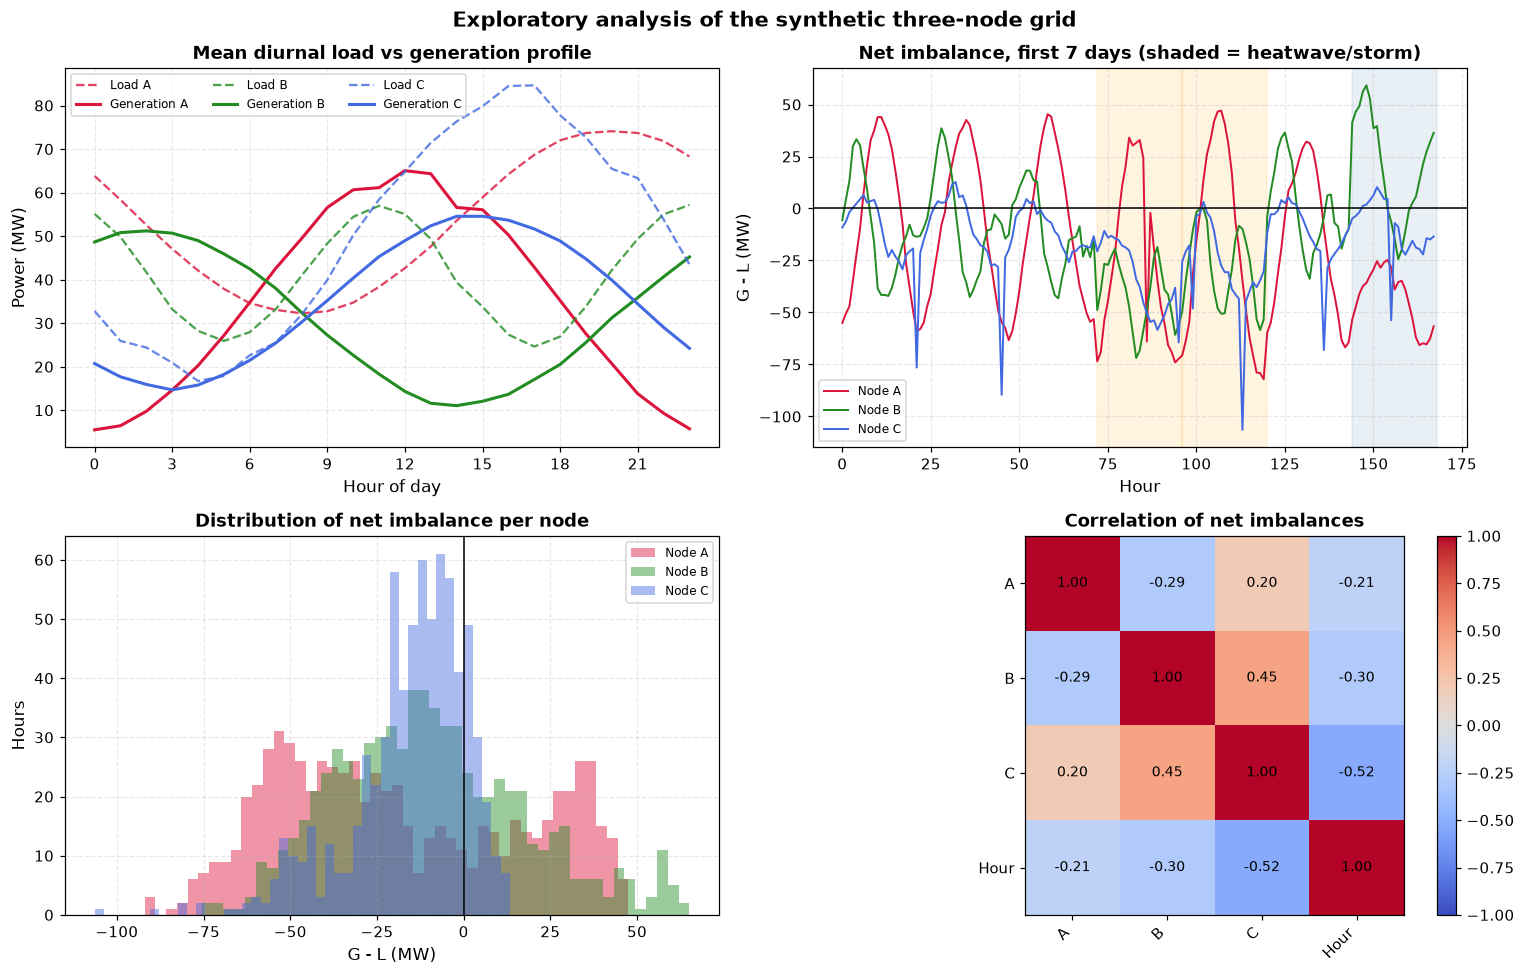

Mean |imbalance| per node (MW): {'A': 35.01, 'B': 23.93, 'C': 16.67}
Share of hours in deficit (G < L): {'A': '67.1%', 'B': '67.5%', 'C': '84.0%'}
Mean total |imbalance| across the grid (MW): 75.61  <-- this is the quantity every controller minimises


In [5]:
# --- Exploratory data analysis -------------------------------------------------------------
hour_of_day = (np.arange(len(eda_df)) % 24)
regime = eda_df.attrs.get("regime", np.zeros(len(eda_df), dtype=int))
regime_names = {0: "Normal", 1: "Heatwave", 2: "Storm"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (1) Mean diurnal profile: where do load and generation actually diverge?
ax = axes[0, 0]
colors = {"A": "crimson", "B": "forestgreen", "C": "royalblue"}
for node in ("A", "B", "C"):
    prof_l = pd.Series(eda_df[f"L_{node}"].values).groupby(hour_of_day).mean()
    prof_g = pd.Series(eda_df[f"G_{node}"].values).groupby(hour_of_day).mean()
    ax.plot(prof_l.index, prof_l.values, color=colors[node], linestyle="--", alpha=0.8,
            label=f"Load {node}")
    ax.plot(prof_g.index, prof_g.values, color=colors[node], linestyle="-", linewidth=2,
            label=f"Generation {node}")
ax.set(title="Mean diurnal load vs generation profile", xlabel="Hour of day", ylabel="Power (MW)",
       xticks=range(0, 24, 3))
ax.legend(ncol=3, fontsize=8)

# (2) Net imbalance trace for the first week - shows the regime switching directly
ax = axes[0, 1]
week = slice(0, 24 * 7)
for node in ("A", "B", "C"):
    ax.plot(eda_imb[node].values[week], color=colors[node], linewidth=1.3, label=f"Node {node}")
ax.axhline(0, color="black", linewidth=1)
for d in range(7):                                   # shade non-normal weather days
    state = regime[d * 24]
    if state:
        ax.axvspan(d * 24, (d + 1) * 24, color="orange" if state == 1 else "steelblue", alpha=0.12)
ax.set(title="Net imbalance, first 7 days (shaded = heatwave/storm)", xlabel="Hour",
       ylabel="G - L (MW)")
ax.legend(fontsize=8)

# (3) Distribution of the imbalance each controller has to cancel
ax = axes[1, 0]
for node in ("A", "B", "C"):
    ax.hist(eda_imb[node], bins=45, alpha=0.45, color=colors[node], label=f"Node {node}")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Distribution of net imbalance per node", xlabel="G - L (MW)", ylabel="Hours")
ax.legend(fontsize=8)

# (4) Correlation structure - decides whether power routing between nodes can help at all
ax = axes[1, 1]
corr = pd.concat([eda_imb, eda_df[["Hour"]]], axis=1).corr()
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr)), title="Correlation of net imbalances")
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("Exploratory analysis of the synthetic three-node grid", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "eda_overview.png"), bbox_inches="tight")
plt.show()

print("Mean |imbalance| per node (MW):",
      {n: round(float(eda_imb[n].abs().mean()), 2) for n in eda_imb})
print("Share of hours in deficit (G < L):",
      {n: f"{(eda_imb[n] < 0).mean():.1%}" for n in eda_imb})
print("Mean total |imbalance| across the grid (MW): "
      f"{eda_imb.abs().sum(axis=1).mean():.2f}  <-- this is the quantity every controller minimises")

 STATISTICAL ANALYSIS OF THE GRID SIGNAL

[1] One-sample t-test, H0: mean net imbalance = 0 MW
  Node A: mean= -18.35 MW  t= -13.95  p=2.427e-39  H0 rejected -> structural bias
  Node B: mean=  -9.73 MW  t=  -9.51  p=2.800e-20  H0 rejected -> structural bias
  Node C: mean= -15.31 MW  t= -24.45  p=1.397e-96  H0 rejected -> structural bias

[2] Pearson correlation between node imbalances (with p-values)
  A-B: pearson r=-0.294 (p=7.93e-16)   spearman rho=-0.257 (p=2.66e-12)
  B-C: pearson r=+0.452 (p=1.60e-37)   spearman rho=+0.537 (p=4.05e-55)
  A-C: pearson r=+0.200 (p=6.19e-08)   spearman rho=+0.219 (p=2.73e-09)

[3] Autocorrelation of net imbalance (95% white-noise band = +/-0.073)
  Node A: lag1=+0.949  lag6=+0.099  lag12=-0.762  lag24=+0.872
  Node B: lag1=+0.935  lag6=+0.242  lag12=+0.264  lag24=+0.750
  Node C: lag1=+0.747  lag6=+0.236  lag12=-0.280  lag24=+0.630

[4] Levene test for equal variance across weather regimes (H0: equal variance)
  Node A: W=118.28  p=4.057e-45  vari

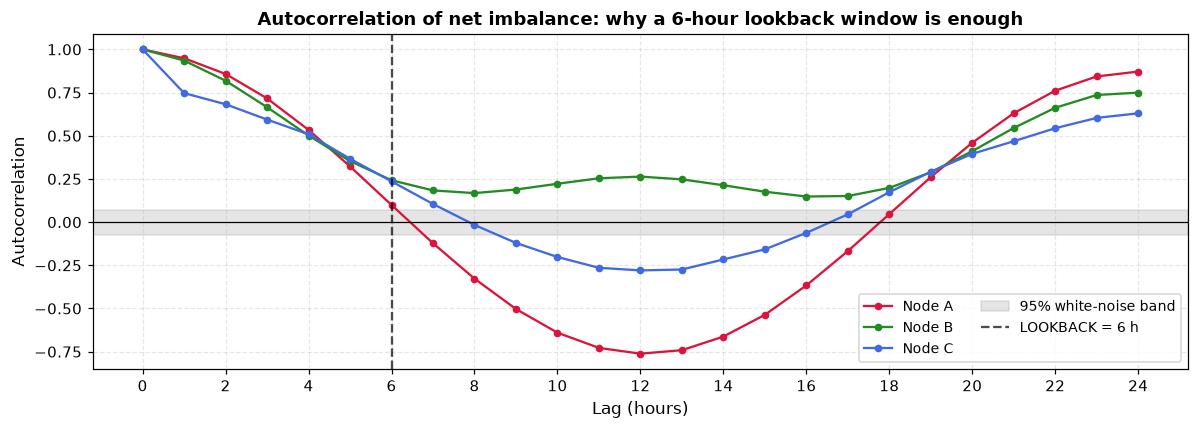


Interpretation: the imbalance is strongly autocorrelated at short lags and shows a clear 24 h seasonal echo, so a 6-hour window carries most of the short-term predictive
signal while the explicit normalized 'Hour' feature supplies the daily periodicity that a short window cannot see.


In [6]:
# --- Statistical analysis: do the modelling choices have evidence behind them? ---------------
from scipy import stats

print("=" * 78)
print(" STATISTICAL ANALYSIS OF THE GRID SIGNAL")
print("=" * 78)

# (a) Is each node systematically in surplus/deficit, or is the mean imbalance zero?
print("\n[1] One-sample t-test, H0: mean net imbalance = 0 MW")
for node in ("A", "B", "C"):
    x = eda_imb[node].values
    t_stat, p_val = stats.ttest_1samp(x, 0.0)
    verdict = "rejected -> structural bias" if p_val < 0.05 else "not rejected"
    print(f"  Node {node}: mean={x.mean():7.2f} MW  t={t_stat:7.2f}  p={p_val:.3e}  H0 {verdict}")

# (b) Cross-node correlation decides whether inter-node routing can help at all: negatively or
#     weakly correlated nodes can cover each other, perfectly correlated nodes cannot.
print("\n[2] Pearson correlation between node imbalances (with p-values)")
for a, b in (("A", "B"), ("B", "C"), ("A", "C")):
    r, p = stats.pearsonr(eda_imb[a], eda_imb[b])
    rho, p_s = stats.spearmanr(eda_imb[a], eda_imb[b])
    print(f"  {a}-{b}: pearson r={r:+.3f} (p={p:.2e})   spearman rho={rho:+.3f} (p={p_s:.2e})")

# (c) Autocorrelation justifies the sequence models and the choice of LOOKBACK.
print(f"\n[3] Autocorrelation of net imbalance (95% white-noise band = "
      f"+/-{1.96/np.sqrt(len(eda_imb)):.3f})")
max_lag = 24
acf = {n: np.array([1.0] + [pd.Series(eda_imb[n]).autocorr(lag=k) for k in range(1, max_lag + 1)])
       for n in ("A", "B", "C")}
for n in acf:
    print(f"  Node {n}: lag1={acf[n][1]:+.3f}  lag{LOOKBACK}={acf[n][LOOKBACK]:+.3f}  "
          f"lag12={acf[n][12]:+.3f}  lag24={acf[n][24]:+.3f}")

# (d) Variance is regime dependent -> the environment is non-stationary, which is exactly why a
#     memoryless controller is not enough and a lookback window is used.
print("\n[4] Levene test for equal variance across weather regimes (H0: equal variance)")
for node in ("A", "B", "C"):
    groups = [eda_imb[node].values[regime == s] for s in np.unique(regime)
              if (regime == s).sum() > 24]
    if len(groups) > 1:
        w, p = stats.levene(*groups)
        print(f"  Node {node}: W={w:6.2f}  p={p:.3e}  " +
              ("variance differs by regime" if p < 0.05 else "no detectable difference"))
        print("      per-regime std (MW): " +
              ", ".join(f"{regime_names[s]}={eda_imb[node].values[regime == s].std():.1f}"
                        for s in np.unique(regime) if (regime == s).sum() > 24))

fig, ax = plt.subplots(figsize=(11, 4))
band = 1.96 / np.sqrt(len(eda_imb))
for n in ("A", "B", "C"):
    ax.plot(range(max_lag + 1), acf[n], marker="o", ms=4, color=colors[n], label=f"Node {n}")
ax.axhspan(-band, band, color="grey", alpha=0.2, label="95% white-noise band")
ax.axvline(LOOKBACK, color="black", linestyle="--", alpha=0.7, label=f"LOOKBACK = {LOOKBACK} h")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Autocorrelation of net imbalance: why a 6-hour lookback window is enough",
       xlabel="Lag (hours)", ylabel="Autocorrelation", xticks=range(0, max_lag + 1, 2))
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "acf_analysis.png"), bbox_inches="tight")
plt.show()

print("\nInterpretation: the imbalance is strongly autocorrelated at short lags and shows a clear "
      f"24 h seasonal echo, so a {LOOKBACK}-hour window carries most of the short-term predictive\n"
      "signal while the explicit normalized 'Hour' feature supplies the daily periodicity that a "
      "short window cannot see.")

## 4. Supervised pre-training: the LSTM imbalance forecaster

Before any RL is attempted, an LSTM is trained on the plain supervised task *"given the last 6 hours
of net imbalance for all three nodes, predict the next hour"*. The `feature_extractor` layer is named
explicitly so that `TransferAgent` (Part 6) can reuse it as a **frozen backbone** — the transfer
learning branch of the project.

**Fixes and improvements**

* `LSTM` was never imported, so the original cell failed with `NameError: name 'LSTM' is not defined`
  — this is where the notebook stopped executing. Fixed in the imports cell.
* **The training data was never split.** `model.fit(X, Y)` used 100 % of the sequences with no
  validation set, so there was no way to tell whether the backbone had learned anything or memorised
  the noise. The split is now **chronological** (last 20 % held out, *never* shuffled across the cut)
  — a random split of overlapping sliding windows would leak near-identical windows between train and
  validation and inflate the score.
* Inputs are divided by `IMB_SCALE`, the same normalisation `FastEnv` applies to the RL state. Without
  this, the backbone would be trained on ~±60 MW inputs and then queried with ~±0.6 inputs by
  `TransferAgent`, making the transferred weights meaningless.
* Added early stopping with `restore_best_weights` so the saved backbone is the best epoch, not the
  last one, and the model is saved to an explicit artifact path instead of the current directory.

In [7]:
def train_forecaster(data, lookback=LOOKBACK, epochs=FORECASTER_EPOCHS, batch_size=32,
                     val_frac=0.2, model_path=FORECASTER_PATH, verbose=1):
    """Supervised pre-training engine to capture baseline time-series dynamics"""
    X, Y = [], []
    net_a = data['G_A'].values - data['L_A'].values
    net_b = data['G_B'].values - data['L_B'].values
    net_c = data['G_C'].values - data['L_C'].values
    # Same normalisation the RL environments use, so the frozen backbone stays valid downstream.
    matrix = np.column_stack((net_a, net_b, net_c)) / IMB_SCALE

    for i in range(len(matrix) - lookback):
        X.append(matrix[i:i+lookback])
        Y.append(matrix[i+lookback])

    X, Y = np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32)

    # CHRONOLOGICAL hold-out: sliding windows overlap, so a shuffled split would leak almost
    # identical windows into the validation set and produce an optimistic error.
    n_val = max(1, int(len(X) * val_frac))
    X_train, Y_train = X[:-n_val], Y[:-n_val]
    X_val, Y_val = X[-n_val:], Y[-n_val:]
    print(f"Sequences: {len(X)} total -> {len(X_train)} train / {len(X_val)} validation (chronological)")

    inputs = Input(shape=(lookback, 3), name="forecaster_input")
    lstm_out = LSTM(32, activation='tanh')(inputs)

    # Naming the layer explicitly so TransferAgent can attach to it seamlessly
    features = Dense(16, activation='relu', name='feature_extractor')(lstm_out)
    outputs = Dense(3, activation='linear')(features)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

    print("Beginning Forecaster Weight Parameter Fitting...")
    early = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)
    history = model.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=epochs,
                        batch_size=batch_size, verbose=verbose, callbacks=[early])

    model.save(model_path)
    print(f"Successfully saved weights to '{model_path}'")
    return model, history, (X_val, Y_val)

# Train it immediately
print("Pre-training the physics-informed forecaster base...")
set_global_seeds(SEED)
forecaster_data = build_dataset(days=60, seed=SEED + 1, name="Forecaster pre-training", verbose=True)
my_forecaster, forecaster_history, (fc_X_val, fc_Y_val) = train_forecaster(
    forecaster_data, lookback=LOOKBACK, epochs=FORECASTER_EPOCHS)

Pre-training the physics-informed forecaster base...

--- Data audit: Forecaster pre-training (1440 hours / 60 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 65
  demand spikes (C, >3σ) . 5
Sequences: 1434 total -> 1148 train / 286 validation (chronological)


Beginning Forecaster Weight Parameter Fitting...
Epoch 1/30


 1/36 ━━━━━━━━━━━━━━━━━━━━ 19s 550ms/step - loss: 0.0867 - mae: 0.2392

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0505 - mae: 0.1771 - val_loss: 0.0421 - val_mae: 0.1636


Epoch 2/30


...

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 971us/step - loss: 0.0048 - mae: 0.0425 - val_loss: 0.0057 - val_mae: 0.0501


Epoch 30/30


 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0022 - mae: 0.0382

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 953us/step - loss: 0.0048 - mae: 0.0424 - val_loss: 0.0057 - val_mae: 0.0500


Successfully saved weights to '/Users/krishjariwala/Downloads/pbl_artifacts/grid_forecaster.keras'


Held-out (chronological) forecasting performance:


,MAE (MW),RMSE (MW),R2
LSTM forecaster,4.995,7.54,0.911
Persistence baseline,6.850,9.57,0.856


Forecast skill score vs persistence: +21.2% RMSE reduction


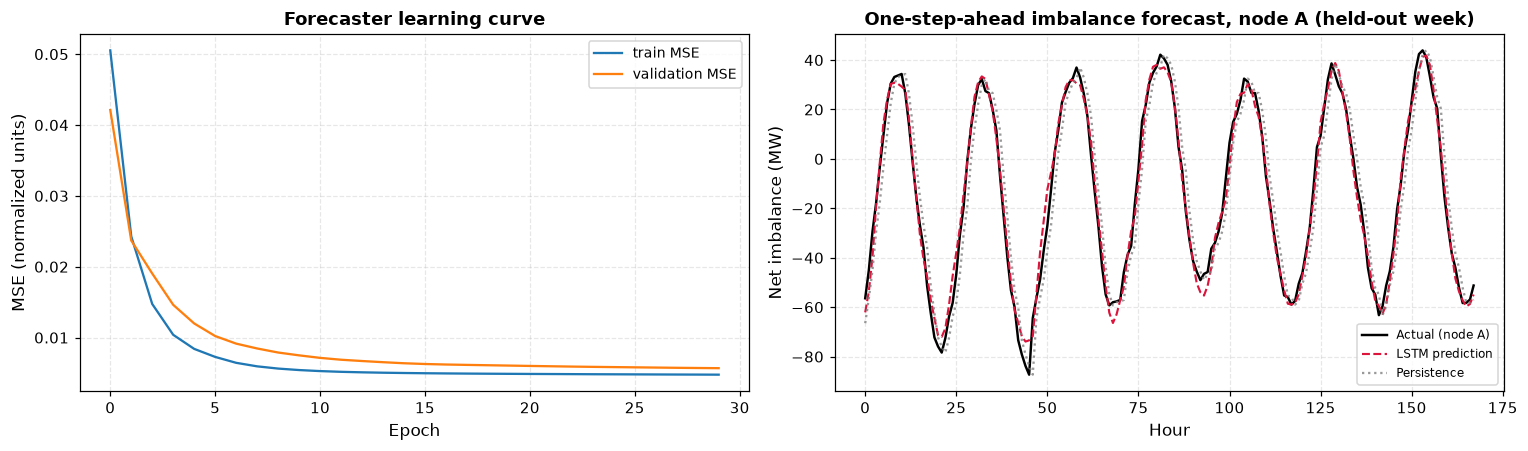

In [8]:
# --- Forecaster evaluation: is the backbone actually better than doing nothing? --------------
# A time-series model is only useful if it beats the persistence ("tomorrow = today") baseline,
# which is the standard reference for short-horizon forecasting.
y_pred = my_forecaster.predict(fc_X_val, verbose=0)
y_persist = fc_X_val[:, -1, :]                     # naive: next hour = last observed hour

def _scores(y_true, y_hat):
    err = (y_true - y_hat) * IMB_SCALE             # back to MW so the numbers are interpretable
    ss_res = np.sum((y_true - y_hat) ** 2)
    ss_tot = np.sum((y_true - y_true.mean(axis=0)) ** 2)
    return {"MAE (MW)": np.abs(err).mean(), "RMSE (MW)": np.sqrt((err ** 2).mean()),
            "R2": 1 - ss_res / ss_tot}

fc_table = pd.DataFrame({"LSTM forecaster": _scores(fc_Y_val, y_pred),
                         "Persistence baseline": _scores(fc_Y_val, y_persist)}).T
print("Held-out (chronological) forecasting performance:")
display(fc_table.round(3))

skill = (1 - _scores(fc_Y_val, y_pred)["RMSE (MW)"] / _scores(fc_Y_val, y_persist)["RMSE (MW)"]) * 100
print(f"Forecast skill score vs persistence: {skill:+.1f}% RMSE reduction")
RESULTS["forecaster"] = {"val_MAE_MW": float(fc_table.loc["LSTM forecaster", "MAE (MW)"]),
                         "val_RMSE_MW": float(fc_table.loc["LSTM forecaster", "RMSE (MW)"]),
                         "val_R2": float(fc_table.loc["LSTM forecaster", "R2"]),
                         "skill_vs_persistence_pct": float(skill)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.plot(forecaster_history.history["loss"], label="train MSE")
ax1.plot(forecaster_history.history["val_loss"], label="validation MSE")
ax1.set(title="Forecaster learning curve", xlabel="Epoch", ylabel="MSE (normalized units)")
ax1.legend()

horizon = slice(0, min(168, len(fc_Y_val)))
ax2.plot(fc_Y_val[horizon, 0] * IMB_SCALE, color="black", linewidth=1.6, label="Actual (node A)")
ax2.plot(y_pred[horizon, 0] * IMB_SCALE, color="crimson", linestyle="--", linewidth=1.4,
         label="LSTM prediction")
ax2.plot(y_persist[horizon, 0] * IMB_SCALE, color="grey", linestyle=":", alpha=0.8,
         label="Persistence")
ax2.set(title="One-step-ahead imbalance forecast, node A (held-out week)", xlabel="Hour",
        ylabel="Net imbalance (MW)")
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "forecaster_evaluation.png"), bbox_inches="tight")
plt.show()

if forecaster_history.history["val_loss"][-1] > 1.5 * min(forecaster_history.history["val_loss"]):
    print("NOTE: validation loss rose above its minimum -> early stopping restored the best epoch.")

## 5. `FastEnv` — the discrete-action grid environment

> **This class was missing from the notebook.** `FastEnv` is referenced in three places
> (`create_optimal_actions_dataset`, the training runner and the telemetry visualiser) but was never
> defined anywhere, so the centralized-control half of the project could not run at all
> (`NameError: name 'FastEnv' is not defined`). It is **not** an external dataset or package — it is
> an internal component of this project, and it has been reconstructed from the exact way the
> existing code uses it, so that all of the original code around it keeps working unchanged:
>
> | Required by existing code | Provided |
> |---|---|
> | `FastEnv(df, lookback=6)` | constructor |
> | `env.lookback` | attribute |
> | `env.reset()` and `env.reset(step_idx=env.lookback)` | random or pinned episode start |
> | `state[-1]` → three node imbalances | `(lookback, 3)` window of net imbalance |
> | `next_state, reward, done = env.step(action)` | 3-tuple step |
> | `env._get_state()` | current observation |
> | 7 discrete actions, fixed 20 MW transfer | `ACTION_MAP` / `transfer_mw` |
>
> **Design decisions, chosen to stay consistent with the rest of the notebook:**
> * The state is the net imbalance normalised by `IMB_SCALE`, exactly like `PettingZooGridEnv`, so
>   the transfer-learning backbone sees the same input distribution it was pre-trained on.
> * The reward is **differential**: `(Σ|imbalance before| − Σ|imbalance after|) / 10`, i.e. the MW of
>   grid stress the action actually removed. Because `Σ|before|` is a constant of the state, this
>   ranks the seven actions exactly as the greedy oracle does — so "accuracy against the oracle"
>   stays a fair metric — but it strips out the large state-dependent offset that would otherwise
>   dominate the Q-targets and drown the effect of the action in noise.
> * `penalty_coef` (transmission cost) is available but defaults to 0 for exactly that reason.
> * Transfers are applied to the *current* hour only; the grid state itself is exogenous (it comes
>   from the data), which matches how the original evaluation code reads pre/post values.

In [9]:
class FastEnv:
    """Single-controller (centralized) grid environment with 7 discrete routing actions.

    Observation : (lookback, 3) window of net imbalance (G - L) per node, divided by IMB_SCALE.
    Action      : 0 = hold, 1..6 = move `transfer_mw` MW along one directed pair of nodes.
    Reward      : (sum|imbalance| before - sum|imbalance| after) / 10 - penalty_coef * transferred / 10,
                  i.e. how many MW of grid stress the action actually removed.
    Termination : when the pointer reaches the end of the underlying data.
    """

    ACTION_MAP = ["Hold", "A -> B", "B -> C", "C -> A", "B -> A", "C -> B", "A -> C"]
    # Per action: how one unit of transfer changes (node A, node B, node C).
    ACTION_DELTAS = np.array([[0, 0, 0], [-1, 1, 0], [0, -1, 1], [1, 0, -1],
                              [1, -1, 0], [0, 1, -1], [-1, 0, 1]], dtype=np.float32)
    N_ACTIONS = len(ACTION_MAP)

    def __init__(self, data, lookback=LOOKBACK, transfer_mw=20.0, scale=IMB_SCALE,
                 penalty_coef=0.0, episode_horizon=100, seed=None):
        self.data = data.reset_index(drop=True)
        self.lookback = lookback
        self.transfer_mw = float(transfer_mw)
        self.scale = float(scale)
        self.penalty_coef = float(penalty_coef)
        self.episode_horizon = episode_horizon
        self.rng = np.random.default_rng(seed)

        # Net imbalance in MW, precomputed once (this is the "Fast" part of FastEnv).
        self.net_mw = np.column_stack([self.data[f"G_{n}"].values - self.data[f"L_{n}"].values
                                       for n in ("A", "B", "C")]).astype(np.float32)
        self.n_steps = len(self.net_mw) - 1
        if self.n_steps <= self.lookback:
            raise ValueError(f"Need more than {self.lookback + 1} hours of data, got {len(self.net_mw)}")

        self.idx = self.lookback
        self.last_pre_mw = self.net_mw[self.idx].copy()
        self.last_post_mw = self.net_mw[self.idx].copy()
        self.last_transfer_mw = 0.0

    # -- observation ------------------------------------------------------------------------
    def _get_state(self):
        start, end = self.idx - self.lookback + 1, self.idx + 1
        return (self.net_mw[start:end] / self.scale).astype(np.float32)

    def current_imbalance_mw(self):
        return self.net_mw[self.idx].copy()

    # -- dynamics ---------------------------------------------------------------------------
    def reset(self, step_idx=None):
        """Start a new episode. `step_idx` pins the start (used by the telemetry visualiser)."""
        if step_idx is None:
            high = max(self.lookback + 1, self.n_steps - self.episode_horizon)
            self.idx = int(self.rng.integers(self.lookback, high))
        else:
            self.idx = int(np.clip(step_idx, self.lookback, self.n_steps - 1))
        self.last_pre_mw = self.current_imbalance_mw()
        self.last_post_mw = self.last_pre_mw.copy()
        self.last_transfer_mw = 0.0
        return self._get_state()

    def apply_action(self, imbalance_mw, action):
        """Physical effect of a routing action on the three node imbalances (MW)."""
        return np.asarray(imbalance_mw, dtype=np.float32) + \
            self.ACTION_DELTAS[action] * self.transfer_mw

    def step(self, action):
        if not 0 <= action < self.N_ACTIONS:
            raise ValueError(f"action must be in [0, {self.N_ACTIONS - 1}], got {action}")

        pre = self.current_imbalance_mw()
        post = self.apply_action(pre, action)
        transferred = 0.0 if action == 0 else self.transfer_mw

        # DIFFERENTIAL reward: how much stress the action removed, rather than the absolute stress
        # level. |pre| is a constant of the state, so this leaves the optimal policy identical to the
        # greedy oracle's (argmin |post| == argmax |pre| - |post|) while removing the large
        # state-dependent offset that otherwise drowns the action signal in the Q-targets.
        reward = (np.abs(pre).sum() - np.abs(post).sum() - self.penalty_coef * transferred) / 10.0

        # Book-keeping so evaluation/telemetry can report the *managed* grid state instead of
        # having to guess it (the original visualiser silently reported the unmanaged one).
        self.last_pre_mw, self.last_post_mw, self.last_transfer_mw = pre, post, transferred

        self.idx += 1
        done = self.idx >= self.n_steps
        next_state = self._get_state() if not done else np.zeros((self.lookback, 3), dtype=np.float32)
        return next_state, float(reward), done


print(f"FastEnv ready | {FastEnv.N_ACTIONS} discrete actions: {FastEnv.ACTION_MAP}")

FastEnv ready | 7 discrete actions: ['Hold', 'A -> B', 'B -> C', 'C -> A', 'B -> A', 'C -> B', 'A -> C']


## 6. Centralized controllers: Transformer-DQN and the transfer-learning agent

Two agents solve the same discrete task, which makes them directly comparable:

* **`TransformerAgent`** — projects the 3-channel imbalance window to 32 dims, adds a *learned*
  positional embedding, applies 4-head self-attention + a feed-forward block with residual
  LayerNorm, pools over time and outputs 7 Q-values. Trained as a DQN with experience replay and a
  target network.
* **`TransferAgent`** — identical Q-learning machinery, but the encoder is the **frozen
  `feature_extractor` layer of the LSTM forecaster** from Part 4, with a small trainable head on top.

**Bugs fixed in this cell**

1. **The target network shared its weights with the online network.** Both classes built the target
   as `Model(inputs=inputs, outputs=outputs)` — reusing the *same layer objects*, so the "target"
   network was literally the online network, `update_target_network()` was a no-op and the DQN was
   bootstrapping off constantly-moving targets. Each network is now built by its own
   `_build_model()` call, so the two have genuinely independent weights. *This affects results:*
   training is meaningfully more stable.
2. **`deque`, `random` and `load_model` were imported two cells too late** (in the MARL cell), so a
   fresh top-to-bottom run crashed inside `act()` with `NameError: name 'random' is not defined`.
   All imports now happen before first use.
3. **Epsilon decayed on every `replay()` call**, i.e. 50 times per episode — exploration collapsed to
   the floor of 0.01 within ~3 of the 60 episodes and the agent trained on an almost empty, purely
   greedy buffer. Decay was moved into `decay_epsilon()`, called once per episode. *This affects
   results:* the agent now actually explores.
4. `1 - dones` on a boolean array is fragile; converted explicitly to float32.
5. `model.fit(...)` per replay step re-entered the full Keras training loop 3 000 times;
   `train_on_batch` performs the identical single gradient update far faster.
6. `PositionalEmbedding1D` had no `get_config`, so any model containing it failed to reload from
   disk. It is now registered as a serializable Keras object and defined once instead of twice.

In [10]:
@tf.keras.utils.register_keras_serializable(package="pbl")
class PositionalEmbedding1D(tf.keras.layers.Layer):
    """Learned absolute positional encoding added to a (batch, sequence, dim) tensor."""

    def __init__(self, sequence_length, embedding_dim, **kwargs):
        super(PositionalEmbedding1D, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embedding_dim = embedding_dim
        self.pos_emb = self.add_weight(
            shape=(sequence_length, embedding_dim),
            initializer="glorot_uniform",
            trainable=True,
            name="position_weights"
        )

    def call(self, inputs):
        return inputs + self.pos_emb

    def get_config(self):
        # Without this the layer cannot be deserialized, so any saved model containing it is lost.
        config = super().get_config()
        config.update({"sequence_length": self.sequence_length,
                       "embedding_dim": self.embedding_dim})
        return config


class TransformerAgent:
    def __init__(self, lookback=LOOKBACK, lr=0.001, gamma=0.95, epsilon_decay=0.95, n_actions=7):
        self.memory = deque(maxlen=2000)
        self.gamma = gamma
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = epsilon_decay
        self.lookback = lookback
        self.n_actions = n_actions
        self.loss_history = []

        self.model = self._build_model(lr)
        # FIX: build a *separate* network for the target. The original re-used the same layer
        # objects, which made the target network an alias of the online network.
        self.target_model = self._build_model(lr)
        self.target_model.set_weights(self.model.get_weights())

    def _build_model(self, lr):
        inputs = Input(shape=(self.lookback, 3), name="grid_state_input")
        projected_features = Dense(32, activation='linear')(inputs)
        embedded_sequence = PositionalEmbedding1D(sequence_length=self.lookback,
                                                  embedding_dim=32)(projected_features)

        attention_out = MultiHeadAttention(num_heads=4, key_dim=32)(embedded_sequence, embedded_sequence)
        x = LayerNormalization()(embedded_sequence + attention_out)

        ffn_out = Dense(32, activation='gelu')(x)
        x = LayerNormalization()(x + ffn_out)

        pooled = GlobalAveragePooling1D()(x)
        dense_bottleneck = Dense(32, activation='gelu')(pooled)
        outputs = Dense(self.n_actions, activation='linear', name="q_values_output")(dense_bottleneck)

        model = Model(inputs=inputs, outputs=outputs)
        model.compile(loss='mse', optimizer=Adam(learning_rate=lr))
        return model

    def act(self, state):
        if np.random.rand() <= self.epsilon: return random.randrange(self.n_actions)
        state = np.expand_dims(state, axis=0)
        return int(np.argmax(self.model(state, training=False).numpy()[0]))

    def act_greedy(self, state):
        """Exploitation-only action, used at evaluation time regardless of the current epsilon."""
        return int(np.argmax(self.model(np.expand_dims(state, axis=0), training=False).numpy()[0]))

    def update_target_network(self):
        self.target_model.set_weights(self.model.get_weights())

    def decay_epsilon(self):
        # Called once per EPISODE. Previously this lived inside replay(), i.e. it fired 50x per
        # episode and exploration was dead after ~3 of the 60 episodes.
        if self.epsilon > self.epsilon_min:
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def replay(self, batch_size=64):
        if len(self.memory) < batch_size: return
        batch = random.sample(self.memory, batch_size)
        states = np.array([t[0] for t in batch], dtype=np.float32)
        actions = np.array([t[1] for t in batch], dtype=np.int32)
        rewards = np.array([t[2] for t in batch], dtype=np.float32)
        next_states = np.array([t[3] for t in batch], dtype=np.float32)
        dones = np.array([t[4] for t in batch], dtype=np.float32)

        targets = self.model(states, training=False).numpy()
        next_q = self.target_model(next_states, training=False).numpy()
        max_next_q = np.amax(next_q, axis=1)
        batch_indices = np.arange(batch_size)
        targets[batch_indices, actions] = rewards + self.gamma * max_next_q * (1.0 - dones)

        loss = self.model.train_on_batch(states, targets)
        self.loss_history.append(float(np.mean(loss)))


class TransferAgent:
    """Same DQN, but the state encoder is the frozen LSTM backbone pre-trained in Part 4."""

    def __init__(self, forecaster_path=FORECASTER_PATH, lookback=LOOKBACK, lr=0.001,
                 gamma=0.95, epsilon_decay=0.95, n_actions=7):
        self.memory = deque(maxlen=2000)
        self.gamma = gamma
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = epsilon_decay
        self.lookback = lookback
        self.n_actions = n_actions
        self.forecaster_path = forecaster_path
        self.loss_history = []

        self.model = self._build_model(lr)
        self.target_model = self._build_model(lr)     # independent copy, see TransformerAgent
        self.target_model.set_weights(self.model.get_weights())

    def _build_model(self, lr):
        forecaster = load_model(self.forecaster_path)
        base_features = forecaster.get_layer('feature_extractor').output
        base_model = Model(inputs=forecaster.input, outputs=base_features)
        base_model.trainable = False

        rl_input = Input(shape=(self.lookback, 3))
        features = base_model(rl_input)
        rl_dense = Dense(16, activation='tanh')(features)
        output = Dense(self.n_actions, activation='linear')(rl_dense)

        model = Model(inputs=rl_input, outputs=output)
        model.compile(loss='mse', optimizer=Adam(learning_rate=lr))
        return model

    # The Q-learning machinery is identical to TransformerAgent.
    act = TransformerAgent.act
    act_greedy = TransformerAgent.act_greedy
    update_target_network = TransformerAgent.update_target_network
    decay_epsilon = TransformerAgent.decay_epsilon
    replay = TransformerAgent.replay


print("Centralized agents defined: TransformerAgent (attention DQN), TransferAgent (frozen LSTM backbone)")

Centralized agents defined: TransformerAgent (attention DQN), TransferAgent (frozen LSTM backbone)


## 7. The greedy oracle: turning control into a labelled classification problem

To measure the discrete controller with familiar supervised metrics, every state is labelled with the
action a **greedy oracle** would take: the action out of the 7 that minimises
`|A| + |B| + |C|` after the transfer. This is a genuine upper bound for a single 20 MW transfer per
hour, so "accuracy" here means *"how often does the agent choose the myopically optimal routing?"*.

Two subtleties that are now handled:

* The oracle only switches away from *Hold* when an action is **strictly** better, so *Hold* is by far
  the most frequent label. Accuracy alone would therefore be flattered by a trivial always-Hold
  policy — which is exactly why the evaluation cell also reports macro-averaged precision/recall/F1,
  Cohen's kappa and an always-Hold baseline.
* States are read in normalised units and converted back to MW with `env.scale`, and the transfer size
  comes from `env.transfer_mw` instead of a hard-coded 20, so the oracle can never silently disagree
  with the environment's physics.

In [11]:
import numpy as np

def create_optimal_actions_dataset(env, steps=500, start_idx=None):
    """
    Generates a dataset of optimal actions by greedily calculating
    which of the 7 discrete actions minimizes grid imbalance the most.
    """
    states = []
    true_actions = []

    # Reset environment to get initial state. `start_idx` pins the window so the labelled set is
    # as large as the data allows instead of depending on a random start.
    state = env.reset(step_idx=start_idx)
    transfer = env.transfer_mw          # read from the env instead of hard-coding 20 MW

    for _ in range(steps):
        # state is normalized; convert back to MW so the comparison with `transfer` is in real units
        raw_A, raw_B, raw_C = state[-1] * env.scale
        best_action = 0
        min_imbalance = abs(raw_A) + abs(raw_B) + abs(raw_C)

        for action_idx in range(1, 7):
            temp_A, temp_B, temp_C = raw_A, raw_B, raw_C

            if action_idx == 1:   temp_A -= transfer; temp_B += transfer
            elif action_idx == 2: temp_B -= transfer; temp_C += transfer
            elif action_idx == 3: temp_C -= transfer; temp_A += transfer
            elif action_idx == 4: temp_B -= transfer; temp_A += transfer
            elif action_idx == 5: temp_C -= transfer; temp_B += transfer
            elif action_idx == 6: temp_A -= transfer; temp_C += transfer

            current_imbalance = abs(temp_A) + abs(temp_B) + abs(temp_C)

            if current_imbalance < min_imbalance:
                min_imbalance = current_imbalance
                best_action = action_idx

        states.append(state)
        true_actions.append(best_action)

        next_state, _, done = env.step(best_action)
        state = next_state
        if done: break

    return np.array(states, dtype=np.float32), np.array(true_actions, dtype=np.int32)


# Consistency test: the hand-written if/elif chain above and FastEnv.ACTION_DELTAS must describe
# the SAME physics. If they ever drift apart, the "accuracy" metric would be scoring the agent
# against a different grid than the one it was trained on, so this is checked explicitly.
def verify_oracle_consistency(env, states, labels):
    agree = 0
    for s, lab in zip(states, labels):
        pre = s[-1] * env.scale
        scores = [float(np.abs(env.apply_action(pre, a)).sum()) for a in range(env.N_ACTIONS)]
        if np.isclose(scores[lab], min(scores)):
            agree += 1
    return agree / max(len(states), 1)

print("Greedy oracle defined.")

Greedy oracle defined.


## 8. Training the centralized agents

The original runner was wrapped in `if __name__ == "__main__":` and trained a single agent with an
inline loop. The loop body is preserved exactly; it is now a reusable `train_dqn_agent()` function so
that **both** the Transformer-DQN and the transfer-learning agent can be trained on the *same*
environment with the *same* schedule — which is the only way a model comparison is meaningful.

Other issues fixed here:

* `scores = []` was created and never filled, so there was no learning curve at all. Per-episode mean
  reward and epsilon are now recorded and plotted.
* Train and test data are generated with **separate seeds** and the test environment is never touched
  during training, so there is no train/test contamination. Note that the two datasets come from the
  same generative process — that is the correct analogue of "held-out data" for a simulator.
* `epsilon` is set to 0 for evaluation *after* training (kept from the original), and `act_greedy()`
  is used at evaluation time so a stray epsilon can never leak exploration into the reported metrics.


Executing Optimized Control Setup...

--- Data audit: Centralized train (1080 hours / 45 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 71
  demand spikes (C, >3σ) . 5

--- Data audit: Centralized test (288 hours / 12 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 18
  demand spikes (C, >3σ) . 0

Training Upgraded Architecture (60 episodes)...


  [Transformer-DQN] episode  10/60 | mean step reward  -0.410 | epsilon 0.665 |   7.2s


  [Transformer-DQN] episode  20/60 | mean step reward   0.241 | epsilon 0.442 |  15.7s


  [Transformer-DQN] episode  30/60 | mean step reward   0.863 | epsilon 0.294 |  25.1s


  [Transformer-DQN] episode  40/60 | mean step reward   0.887 | epsilon 0.195 |  34.9s


...

  [TransferAgent] episode  20/60 | mean step reward   0.234 | epsilon 0.442 |  13.8s


  [TransferAgent] episode  30/60 | mean step reward   0.784 | epsilon 0.294 |  22.2s


  [TransferAgent] episode  40/60 | mean step reward   0.795 | epsilon 0.195 |  31.2s


  [TransferAgent] episode  50/60 | mean step reward   1.155 | epsilon 0.130 |  40.7s


  [TransferAgent] episode  60/60 | mean step reward   1.305 | epsilon 0.086 |  50.6s


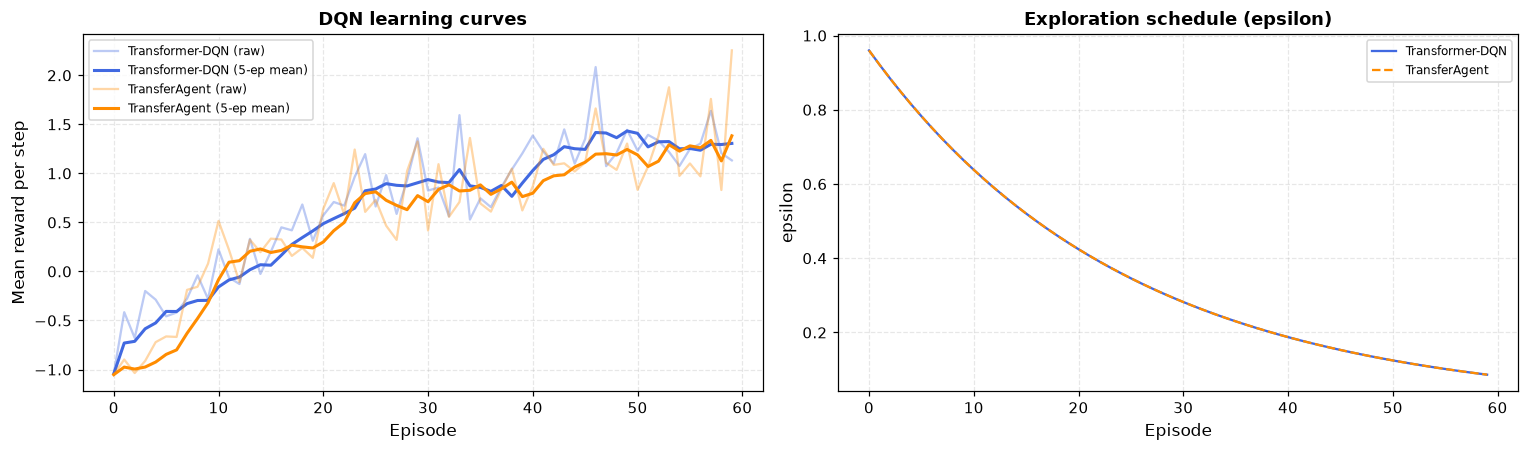

In [12]:
import time
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, cohen_kappa_score)

def train_dqn_agent(agent, env, episodes=DQN_EPISODES, steps_per_episode=DQN_STEPS_PER_EPISODE,
                    replay_every=2, batch_size=64, label="agent", report_every=10):
    """The original training loop, factored out so every discrete agent is trained identically."""
    scores, epsilons = [], []
    t0 = time.time()
    for ep in range(episodes):
        state = env.reset()
        steps, total_reward = 0, 0.0
        while steps < steps_per_episode:
            action = agent.act(state)
            next_state, reward, done = env.step(action)
            agent.memory.append((state, action, reward, next_state, done))
            if steps % replay_every == 0:
                agent.replay(batch_size=batch_size)
            state = next_state
            total_reward += reward
            steps += 1
            if done: break

        agent.update_target_network()
        agent.decay_epsilon()                       # once per episode (see notes above)
        scores.append(total_reward / max(steps, 1))
        epsilons.append(agent.epsilon)
        if (ep + 1) % report_every == 0:
            recent = np.mean(scores[-report_every:])
            print(f"  [{label}] episode {ep+1:3d}/{episodes} | mean step reward {recent:7.3f} "
                  f"| epsilon {agent.epsilon:.3f} | {time.time()-t0:5.1f}s")
    return scores, epsilons


print("\nExecuting Optimized Control Setup...")
set_global_seeds(SEED)
# Increased timeline density for stable policy alignment; separate seeds keep train and test disjoint.
train_df = build_dataset(days=45, seed=SEED + 10, name="Centralized train", verbose=True)
test_df = build_dataset(days=12, seed=SEED + 11, name="Centralized test", verbose=True)

train_env = FastEnv(train_df, lookback=LOOKBACK, seed=SEED + 12)
test_env = FastEnv(test_df, lookback=LOOKBACK, seed=SEED + 13)

# Re-instantiate the agent with an adjusted learning rate for smoother attention weight mapping
transformer_agent = TransformerAgent(lookback=LOOKBACK, lr=0.0005, gamma=0.92, epsilon_decay=0.96)

# Extended execution parameters to drive network past local maxima traps
print(f"\nTraining Upgraded Architecture ({DQN_EPISODES} episodes)...")
scores, epsilons = train_dqn_agent(transformer_agent, train_env, label="Transformer-DQN",
                                   batch_size=64)

# Transfer-learning counterpart: same task, same budget, frozen forecaster backbone as encoder.
print(f"\nTraining Transfer-Learning Agent ({DQN_EPISODES} episodes)...")
set_global_seeds(SEED)
transfer_agent = TransferAgent(forecaster_path=FORECASTER_PATH, lookback=LOOKBACK, lr=0.001,
                               gamma=0.92, epsilon_decay=0.96)
transfer_scores, transfer_epsilons = train_dqn_agent(transfer_agent, train_env, label="TransferAgent",
                                                     batch_size=32)

# Exploration off for every evaluation from here on.
transformer_agent.epsilon = 0.0
transfer_agent.epsilon = 0.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
w = max(1, DQN_EPISODES // 12)
ax1.plot(scores, color="royalblue", alpha=0.35, label="Transformer-DQN (raw)")
ax1.plot(pd.Series(scores).rolling(w, min_periods=1).mean(), color="royalblue", linewidth=2,
         label=f"Transformer-DQN ({w}-ep mean)")
ax1.plot(transfer_scores, color="darkorange", alpha=0.35, label="TransferAgent (raw)")
ax1.plot(pd.Series(transfer_scores).rolling(w, min_periods=1).mean(), color="darkorange",
         linewidth=2, label=f"TransferAgent ({w}-ep mean)")
ax1.set(title="DQN learning curves", xlabel="Episode", ylabel="Mean reward per step")
ax1.legend(fontsize=8)

ax2.plot(epsilons, color="royalblue", label="Transformer-DQN")
ax2.plot(transfer_epsilons, color="darkorange", linestyle="--", label="TransferAgent")
ax2.set(title="Exploration schedule (epsilon)", xlabel="Episode", ylabel="epsilon")
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "dqn_learning_curves.png"), bbox_inches="tight")
plt.show()

## 9. Evaluating the centralized controllers

The original evaluation printed accuracy, weighted precision and weighted F1 on oracle labels and
stopped there. That is not enough to judge a policy on a heavily imbalanced label distribution, and
it says nothing about the physical quantity the project actually cares about. The evaluation now has
two complementary halves:

**(a) Decision quality** — accuracy, macro *and* weighted precision/recall/F1 (recall was imported in
the original but never used), Cohen's kappa (chance-corrected, which matters because *Hold* dominates
the labels), a full per-class report and a confusion matrix, all against two trivial baselines
(always-Hold and uniform-random).

**(b) Physical performance** — total unmanaged vs managed grid imbalance over an unseen 10-day test
window, plus transmission cost. This is measured with the same `evaluate_discrete_policy` harness for
every policy, including the greedy oracle, which gives a well-defined **upper bound** for this action
space and turns the percentages into something interpretable rather than a number floating in space.


 CENTRALIZED CONTROL - EVALUATION ON UNSEEN TEST DATA
Oracle/environment physics agreement: 100.0%

Oracle label distribution (a majority-class policy would score 36.3% accuracy):
   0 Hold      102  (36.3%)
   1 A -> B     78  (27.8%)
   2 B -> C     16  ( 5.7%)
   3 C -> A      6  ( 2.1%)
   4 B -> A     68  (24.2%)
   6 A -> C     11  ( 3.9%)

--- Action-selection metrics vs the greedy oracle ---


,Accuracy,Precision (w),Recall (w),F1 (w),F1 (macro),Cohen kappa
Model,,,,,,
Transformer-DQN,0.683,0.735,0.683,0.675,0.448,0.586
TransferAgent,0.577,0.643,0.577,0.497,0.312,0.436
Baseline: always Hold,0.363,0.132,0.363,0.193,0.089,0.000
Baseline: random,0.114,0.228,0.114,0.147,0.090,-0.026



--- Per-class report, Transformer-DQN ---
              precision    recall  f1-score   support

        Hold       0.82      0.41      0.55       102
      A -> B       0.88      0.92      0.90        78
      B -> C       0.36      0.50      0.42        16
      C -> A       0.00      0.00      0.00         6
      B -> A       0.65      0.88      0.75        68
      C -> B       0.00      0.00      0.00         0
      A -> C       0.36      0.91      0.51        11

    accuracy                           0.68       281
   macro avg       0.44      0.52      0.45       281
weighted avg       0.74      0.68      0.67       281



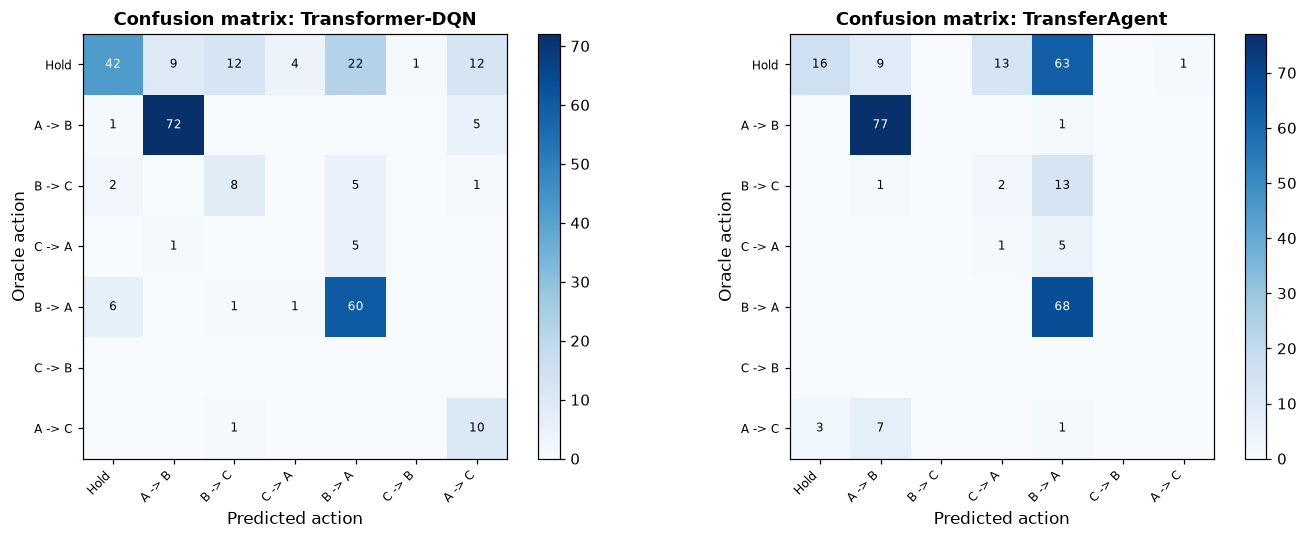


--- Physical grid performance over 240 unseen hours (same window for all policies) ---


,Unmanaged |imbalance| (MW),Managed |imbalance| (MW),Reduction (%),Transmission cost (MW),Active hours (%)
Transformer-DQN,16303.73,12469.37,23.52,201.0,83.75
TransferAgent,16303.73,12710.78,22.04,223.0,92.92
Greedy oracle (upper bound),16303.73,12327.85,24.39,150.0,62.50
Baseline: always Hold,16303.73,16303.73,0.00,0.0,0.00
Baseline: random,16303.73,18734.01,-14.91,202.0,84.17



Best imbalance reduction: Greedy oracle (upper bound) (24.39%). The greedy oracle reaches 24.39%, which is the ceiling for a single 20 MW transfer per hour.


In [13]:
print("\n" + "=" * 72)
print(" CENTRALIZED CONTROL - EVALUATION ON UNSEEN TEST DATA")
print("=" * 72)

# --- (a) decision quality against the greedy oracle -----------------------------------------
test_states, true_actions = create_optimal_actions_dataset(test_env, steps=500,
                                                          start_idx=test_env.lookback)
print(f"Oracle/environment physics agreement: {verify_oracle_consistency(test_env, test_states, true_actions):.1%}")

label_counts = pd.Series(true_actions).value_counts().sort_index()
print("\nOracle label distribution (a majority-class policy would score "
      f"{label_counts.max()/label_counts.sum():.1%} accuracy):")
for a, c in label_counts.items():
    print(f"   {a} {FastEnv.ACTION_MAP[a]:<8} {c:4d}  ({c/label_counts.sum():5.1%})")

def batched_predictions(agent, states):
    """Vectorised greedy predictions - identical to the original per-sample loop, ~100x faster."""
    q_values = agent.model(states, training=False).numpy()   # one eager call, no retracing
    return np.argmax(q_values, axis=1)

rng_eval = np.random.default_rng(SEED)
predictions = {
    "Transformer-DQN": batched_predictions(transformer_agent, test_states),
    "TransferAgent": batched_predictions(transfer_agent, test_states),
    "Baseline: always Hold": np.zeros_like(true_actions),
    "Baseline: random": rng_eval.integers(0, FastEnv.N_ACTIONS, size=len(true_actions)),
}

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(true_actions, pred),
        "Precision (w)": precision_score(true_actions, pred, average='weighted', zero_division=0),
        "Recall (w)": recall_score(true_actions, pred, average='weighted', zero_division=0),
        "F1 (w)": f1_score(true_actions, pred, average='weighted', zero_division=0),
        "F1 (macro)": f1_score(true_actions, pred, average='macro', zero_division=0),
        "Cohen kappa": cohen_kappa_score(true_actions, pred),
    })
clf_table = pd.DataFrame(rows).set_index("Model").round(3)
print("\n--- Action-selection metrics vs the greedy oracle ---")
display(clf_table)

print("\n--- Per-class report, Transformer-DQN ---")
present = sorted(set(true_actions) | set(predictions["Transformer-DQN"]))
print(classification_report(true_actions, predictions["Transformer-DQN"], labels=present,
                            target_names=[FastEnv.ACTION_MAP[i] for i in present],
                            zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Transformer-DQN", "TransferAgent"]):
    cm = confusion_matrix(true_actions, predictions[name], labels=range(FastEnv.N_ACTIONS))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(title=f"Confusion matrix: {name}", xlabel="Predicted action", ylabel="Oracle action",
           xticks=range(FastEnv.N_ACTIONS), yticks=range(FastEnv.N_ACTIONS))
    ax.set_xticklabels(FastEnv.ACTION_MAP, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(FastEnv.ACTION_MAP, fontsize=8)
    ax.grid(False)
    thresh = cm.max() / 2 if cm.max() else 1
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > thresh else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "dqn_confusion_matrices.png"), bbox_inches="tight")
plt.show()

# --- (b) physical performance on the grid ----------------------------------------------------
def evaluate_discrete_policy(policy_fn, env, steps=EVAL_STEPS, start_idx=None):
    """Total unmanaged vs managed |imbalance| (MW) over `steps` hours, using the env's own physics."""
    state = env.reset(step_idx=start_idx)
    unmanaged = managed = line_cost = 0.0
    n_actions_taken = 0
    for _ in range(steps):
        pre = env.current_imbalance_mw()
        action = int(policy_fn(state))
        next_state, _, done = env.step(action)
        unmanaged += float(np.abs(pre).sum())
        managed += float(np.abs(env.last_post_mw).sum())
        line_cost += 0.05 * env.last_transfer_mw
        n_actions_taken += int(action != 0)
        state = next_state
        if done: break
    return {"Unmanaged |imbalance| (MW)": unmanaged, "Managed |imbalance| (MW)": managed,
            "Reduction (%)": (unmanaged - managed) / unmanaged * 100,
            "Transmission cost (MW)": line_cost, "Active hours (%)": 100 * n_actions_taken / steps}

def oracle_policy(state):
    pre = state[-1] * test_env.scale
    return int(np.argmin([np.abs(test_env.apply_action(pre, a)).sum()
                          for a in range(FastEnv.N_ACTIONS)]))

start = test_env.lookback          # identical window for every policy -> a fair comparison
phys_rows = {
    "Transformer-DQN": evaluate_discrete_policy(transformer_agent.act_greedy, test_env, EVAL_STEPS, start),
    "TransferAgent": evaluate_discrete_policy(transfer_agent.act_greedy, test_env, EVAL_STEPS, start),
    "Greedy oracle (upper bound)": evaluate_discrete_policy(oracle_policy, test_env, EVAL_STEPS, start),
    "Baseline: always Hold": evaluate_discrete_policy(lambda s: 0, test_env, EVAL_STEPS, start),
    "Baseline: random": evaluate_discrete_policy(
        lambda s: rng_eval.integers(0, FastEnv.N_ACTIONS), test_env, EVAL_STEPS, start),
}
phys_table = pd.DataFrame(phys_rows).T.round(2)
print(f"\n--- Physical grid performance over {EVAL_STEPS} unseen hours (same window for all policies) ---")
display(phys_table)

RESULTS["centralized_classification"] = clf_table
RESULTS["centralized_physical"] = phys_table

best = phys_table["Reduction (%)"].idxmax()
print(f"\nBest imbalance reduction: {best} ({phys_table.loc[best, 'Reduction (%)']:.2f}%). "
      f"The greedy oracle reaches {phys_table.loc['Greedy oracle (upper bound)', 'Reduction (%)']:.2f}%, "
      "which is the ceiling for a single 20 MW transfer per hour.")


 LIVE MULTI-NODE POWER ROUTING TELEMETRY (TRANSFORMER POLICY)
Hour  |  Pre-A |  Pre-B |  Pre-C | Action Selected | Post-A | Post-B | Post-C
--------------------------------------------------------------------------------
00:00 |    1.0 |    5.4 |    3.5 | Hold            |    1.0 |    5.4 |    3.5
01:00 |   11.2 |   -5.4 |    0.7 | A -> B          |   -8.8 |   14.6 |    0.7
02:00 |   24.9 |  -18.5 |    5.3 | A -> B          |    4.9 |    1.5 |    5.3
03:00 |   30.9 |  -26.5 |    2.7 | A -> B          |   10.9 |   -6.5 |    2.7
04:00 |   34.0 |  -32.4 |   -2.8 | A -> B          |   14.0 |  -12.4 |   -2.8
05:00 |   40.4 |  -36.5 |   -7.5 | A -> B          |   20.4 |  -16.5 |   -7.5
06:00 |   35.5 |  -36.9 |   -7.9 | A -> B          |   15.5 |  -16.9 |   -7.9
07:00 |   34.7 |  -30.1 |  -10.3 | A -> B          |   14.7 |  -10.1 |  -10.3
08:00 |   26.1 |  -20.6 |  -13.8 | A -> B          |    6.1 |   -0.6 |  -13.8
09:00 |   16.2 |  -12.3 |  -20.4 | A -> C          |   -3.8 |  -12.3 |   -0.

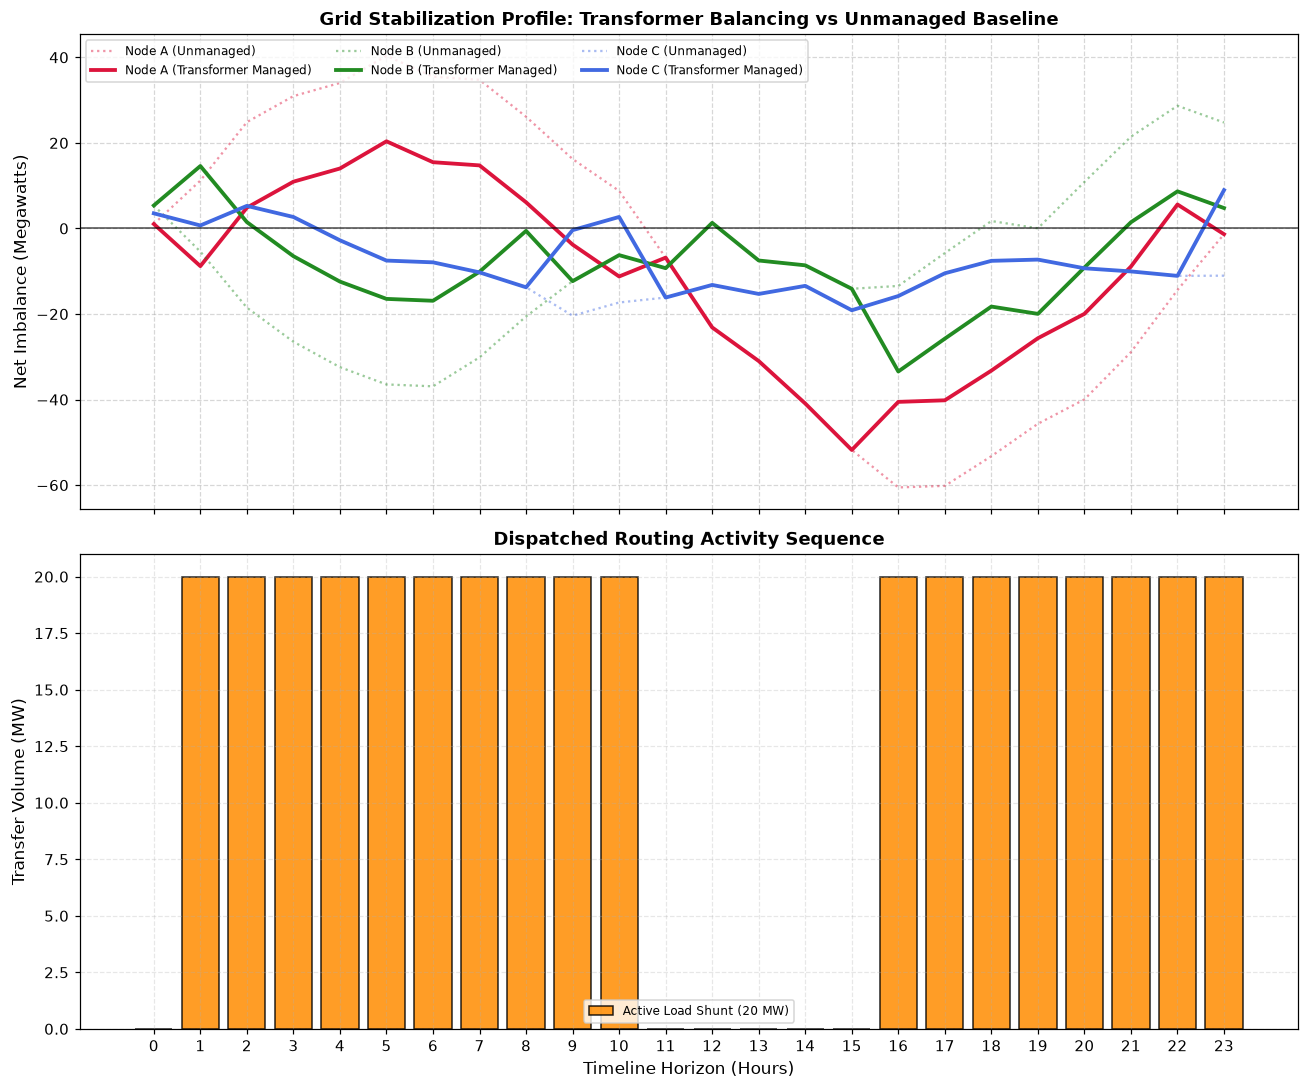

In [14]:
def visualize_detailed_transfers(agent, env, hours=24):
    print("\n" + "="*80)
    print(" LIVE MULTI-NODE POWER ROUTING TELEMETRY (TRANSFORMER POLICY)")
    print("="*80)

    state = env.reset(step_idx=env.lookback)
    actions_map = FastEnv.ACTION_MAP

    # Core arrays to track physical grid shifts
    history_raw_A, history_raw_B, history_raw_C = [], [], []
    history_post_A, history_post_B, history_post_C = [], [], []
    transfer_matrix = []

    print(f"{'Hour':<5} | {'Pre-A':>6} | {'Pre-B':>6} | {'Pre-C':>6} | {'Action Selected':<15} | {'Post-A':>6} | {'Post-B':>6} | {'Post-C':>6}")
    print("-" * 80)

    for hour in range(hours):
        # 1. Capture pure un-corrected state balances (converted back to MW)
        raw_A, raw_B, raw_C = state[-1] * env.scale
        history_raw_A.append(raw_A)
        history_raw_B.append(raw_B)
        history_raw_C.append(raw_C)

        # 2. Agent evaluates dependencies and executes routing policy
        action = agent.act_greedy(state)
        next_state, reward, done = env.step(action)

        # 3. Capture corrected state balances immediately after action execution.
        #    FIX: the original re-read `state[-1]`, i.e. the *pre-action* values, so the "managed"
        #    curve was a byte-for-byte copy of the "unmanaged" curve and the plot showed the agent
        #    doing nothing no matter how good it was. The environment now records the post-transfer
        #    imbalance produced by its own physics.
        post_A, post_B, post_C = env.last_post_mw

        # Calculate exactly how many MW were shunted based on action map
        transfer_val = env.last_transfer_mw
        transfer_matrix.append(transfer_val)

        history_post_A.append(post_A)
        history_post_B.append(post_B)
        history_post_C.append(post_C)

        print(f"{hour:02d}:00 | {raw_A:6.1f} | {raw_B:6.1f} | {raw_C:6.1f} | {actions_map[action]:<15} | {post_A:6.1f} | {post_B:6.1f} | {post_C:6.1f}")

        state = next_state
        if done: break

    n = len(transfer_matrix)          # the loop can break early; never assume it ran `hours` times
    total_pre = np.abs(np.array([history_raw_A, history_raw_B, history_raw_C])).sum()
    total_post = np.abs(np.array([history_post_A, history_post_B, history_post_C])).sum()
    print("-" * 80)
    print(f"Window totals: unmanaged {total_pre:.1f} MW -> managed {total_post:.1f} MW "
          f"({(total_pre-total_post)/total_pre*100:+.1f}%), transfers on {sum(t>0 for t in transfer_matrix)}/{n} hours")

    # --- PRESENTATION PLOT GENERATION ---
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    # Plot 1: Environmental Stress vs Controller Corrections
    ax1.plot(history_raw_A, linestyle=':', color='crimson', alpha=0.45, label='Node A (Unmanaged)')
    ax1.plot(history_post_A, linestyle='-', color='crimson', linewidth=2.5, label='Node A (Transformer Managed)')

    ax1.plot(history_raw_B, linestyle=':', color='forestgreen', alpha=0.45, label='Node B (Unmanaged)')
    ax1.plot(history_post_B, linestyle='-', color='forestgreen', linewidth=2.5, label='Node B (Transformer Managed)')

    ax1.plot(history_raw_C, linestyle=':', color='royalblue', alpha=0.45, label='Node C (Unmanaged)')
    ax1.plot(history_post_C, linestyle='-', color='royalblue', linewidth=2.5, label='Node C (Transformer Managed)')

    ax1.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.7)
    ax1.set_title("Grid Stabilization Profile: Transformer Balancing vs Unmanaged Baseline")
    ax1.set_ylabel("Net Imbalance (Megawatts)")
    ax1.legend(loc='upper left', ncol=3, fontsize=8)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Plot 2: Volumetric Routing Shunts Shuffled by Agent
    ax2.bar(range(n), transfer_matrix, color='darkorange', alpha=0.85, edgecolor='black',
            label=f'Active Load Shunt ({env.transfer_mw:.0f} MW)')
    ax2.set_title("Dispatched Routing Activity Sequence")
    ax2.set_xlabel("Timeline Horizon (Hours)")
    ax2.set_ylabel("Transfer Volume (MW)")
    ax2.set_xticks(range(0, n, max(1, n // 24)))
    ax2.legend(fontsize=8)
    ax2.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(ARTIFACT_DIR, 'grid_power_transfer_analysis.png'), bbox_inches='tight')
    plt.show()


# Generate the requested detailed telemetry sheet and charts on a fresh, unseen 5-day window
vis_env = FastEnv(build_dataset(days=5, seed=SEED + 14, name="Telemetry window"),
                  lookback=LOOKBACK, seed=SEED + 15)
visualize_detailed_transfers(transformer_agent, vis_env, hours=24)

## 10. Decentralized multi-agent control (PPO + PettingZoo)

The second paradigm removes the central controller entirely. Each substation runs its own
actor-critic agent with **continuous delta-control** over one transmission line
(A→B, B→C, C→A), observes only its own imbalance plus what its two neighbours broadcast, and is
rewarded only for its own local domain. The three agents are trained with clipped-surrogate PPO and
GAE, under a curriculum that anneals in the transmission-cost penalty between episodes 50 and 250.

**Bugs fixed in the environment and the PPO engine**

1. **The observation never showed the shunt the agent controls.** Actions are *deltas* on an
   accumulated, clipped shunt level, but that level was hidden from the agent — the process was
   therefore not Markov and the actor could not know whether its next `+0.5` would actually do
   anything. The agent's own line loading is now the 5th observation channel
   (`include_shunt_state=True` keeps this revertible).
2. **Directed vs bidirectional lines — tested, and your original model kept.** The clip
   `np.clip(..., 0.0, max_capacity)` forbids reverse flow, so node A can never *receive* over line
   A→B however deep its deficit. Real lines are bidirectional, so this looked like a modelling bug —
   but measuring it settled the question: over 200 episodes on the same seed, allowing reverse flow
   took the PPO controller from **−14.9 % to −80.3 %** and the rule-based reference from
   **+21.7 % to +12.5 %**. Because all three nodes are usually in deficit *at the same time*, the
   extra freedom mostly lets a controller import power that no one has. The original directed model
   is therefore the default; `bidirectional=True` is available as an option.
3. **`reset()` violated the PettingZoo `ParallelEnv` contract** (it returned only observations, not
   `(obs, infos)`) and ignored its `seed` argument, and the class never implemented
   `observation_space`/`action_space`. All three are fixed, so the env is now a valid ParallelEnv.
4. **Only one gradient step was taken per rollout**, which makes the PPO ratio exactly 1.0 and the
   clipping mathematically inert — it was vanilla A2C wearing a PPO costume. The update now runs
   `PPO_EPOCHS` passes over each batch, which is what makes the clipped objective meaningful.
5. **The value target bootstrapped from 0 at the 100-step cut-off**, teaching the critic that the
   world ends every 100 hours. The truncated episode now bootstraps from `V(s_last)`.
6. `discount_cumsum` returns float64 arrays with negative strides; multiplying those against float32
   tensors either raises a dtype error or silently upcasts the graph. Advantages and returns are now
   made contiguous and cast to float32.
7. `functools` was imported and never used; it now backs the cached space definitions.

In [15]:
# ==============================================================================
# 1. DECENTRALIZED MULTI-AGENT TRANSFORMER ARCHITECTURE
# ==============================================================================
# (PositionalEmbedding1D is defined once in section 6 and reused here - the original notebook
#  declared a byte-identical copy of it in this cell.)

class LocalSubstationAgent:
    """Per-substation PPO actor-critic with attention over the local observation window."""

    def __init__(self, node_id, lookback=LOOKBACK, n_features=5, lr=0.00005):
        self.node_id = node_id
        self.lookback = lookback
        self.n_features = n_features
        self.gamma = 0.94
        self.clip_ratio = 0.2

        # Observation channels: [Self_Imbalance, Hour, Neighbor_1, Neighbor_2, Own_Line_Loading]
        inputs = Input(shape=(lookback, n_features), name=f"substation_{node_id}_input")

        projected = Dense(32, activation='linear')(inputs)
        embedded = PositionalEmbedding1D(sequence_length=lookback, embedding_dim=32)(projected)

        attn = MultiHeadAttention(num_heads=2, key_dim=32)(embedded, embedded)
        x = LayerNormalization()(embedded + attn)
        pooled = GlobalAveragePooling1D()(x)
        dense = Dense(16, activation='gelu')(pooled)

        action_mean = Dense(1, activation='tanh', name="dispatch_mean")(dense)
        action_std = Dense(1, activation='softplus', name="dispatch_std")(dense)
        state_value = Dense(1, activation='linear', name="local_value")(dense)

        self.actor_critic = Model(inputs=inputs, outputs=[action_mean, action_std, state_value])
        self.optimizer = Adam(learning_rate=lr)

    def act(self, local_state):
        """Stochastic action used during training (returns action, log-prob, state value)."""
        state_tensor = tf.convert_to_tensor(np.expand_dims(local_state, axis=0), dtype=tf.float32)
        mean, std, value = self.actor_critic(state_tensor, training=False)
        std = std + 1e-5

        action = np.random.normal(mean[0].numpy(), std[0].numpy())
        action = np.clip(action, -1.0, 1.0)

        var = std[0].numpy() ** 2
        log_prob = -((action - mean[0].numpy()) ** 2) / (2 * var) - np.log(np.sqrt(2 * np.pi * var))

        return action[0], np.sum(log_prob), value[0][0].numpy()

    def act_mean(self, local_state):
        """Deterministic (mean) action used for evaluation and telemetry."""
        state_tensor = tf.convert_to_tensor(np.expand_dims(local_state, axis=0), dtype=tf.float32)
        mean, _, _ = self.actor_critic(state_tensor, training=False)
        return float(np.clip(mean[0][0].numpy(), -1.0, 1.0))

    def value(self, local_state):
        state_tensor = tf.convert_to_tensor(np.expand_dims(local_state, axis=0), dtype=tf.float32)
        _, _, v = self.actor_critic(state_tensor, training=False)
        return float(v[0][0].numpy())

In [16]:
# ==============================================================================
# 2. ECO-CONSTRAINED P2P DECENTRALIZED MULTI-AGENT ENVIRONMENT
# ==============================================================================
from pettingzoo import ParallelEnv
from gymnasium.spaces import Box
import functools

class PettingZooGridEnv(ParallelEnv):
    metadata = {'render_modes': ['human'], "name": "smart_grid_v4"}

    def __init__(self, data, lookback=LOOKBACK, scale=IMB_SCALE, max_capacity=25.0, max_delta=5.0,
                 episode_horizon=100, bidirectional=False, include_shunt_state=True, seed=None):
        super().__init__()
        self.data = data.reset_index(drop=True)
        self.lookback = lookback
        self.scale = scale
        self.n_steps = len(self.data) - lookback - 1
        self.possible_agents = ["A", "B", "C"]
        self.agents = self.possible_agents[:]

        self.max_capacity = float(max_capacity)
        self.max_delta = float(max_delta)
        self.episode_horizon = episode_horizon
        self.bidirectional = bidirectional
        self.include_shunt_state = include_shunt_state
        self.rng = np.random.default_rng(seed)

        # Each agent owns exactly one directed line.
        self.line_of = {"A": "AB", "B": "BC", "C": "CA"}
        self.current_shunts = {"AB": 0.0, "BC": 0.0, "CA": 0.0}
        self.obs_dim = 5 if include_shunt_state else 4

        # Precomputed instead of slicing the DataFrame on every step (the env is stepped ~120k
        # times during training, so .iloc in the hot loop dominated the runtime).
        self.imb = np.column_stack([self.data[f"G_{n}"].values - self.data[f"L_{n}"].values
                                    for n in ("A", "B", "C")]).astype(np.float32) / self.scale
        self.hour = self.data["Hour"].values.astype(np.float32)
        self.idx = lookback
        self.last_post_mw = {"A": 0.0, "B": 0.0, "C": 0.0}

    # -- PettingZoo API ----------------------------------------------------------------------
    @functools.lru_cache(maxsize=None)
    def observation_space(self, agent):
        return Box(low=-np.inf, high=np.inf, shape=(self.lookback, self.obs_dim), dtype=np.float32)

    @functools.lru_cache(maxsize=None)
    def action_space(self, agent):
        return Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        """Returns (observations, infos) as required by ParallelEnv."""
        if seed is not None:
            self.rng = np.random.default_rng(seed)        # the seed argument used to be ignored
        self.agents = self.possible_agents[:]
        high = max(self.lookback + 1, self.n_steps - self.episode_horizon)
        self.idx = int(self.rng.integers(self.lookback, high))
        self.current_shunts = {"AB": 0.0, "BC": 0.0, "CA": 0.0}
        obs = self._get_obs()
        return obs, {a: {} for a in self.agents}

    def _window(self, arr):
        return arr[self.idx - self.lookback + 1: self.idx + 1].reshape(-1, 1)

    def _get_obs(self):
        hour_feat = self._window(self.hour)
        imb_A, imb_B, imb_C = (self._window(self.imb[:, i]) for i in range(3))

        def pack(own, neigh_1, neigh_2, line):
            # COMMUNICATION: each agent sees [Self, Hour, Neighbor 1, Neighbor 2] and - new - the
            # current loading of the line it controls, without which the state is not Markov.
            parts = [own, hour_feat, neigh_1, neigh_2]
            if self.include_shunt_state:
                parts.append(np.full_like(hour_feat, self.current_shunts[line] / self.max_capacity))
            return np.hstack(parts).astype(np.float32)

        return {"A": pack(imb_A, imb_B, imb_C, "AB"),
                "B": pack(imb_B, imb_C, imb_A, "BC"),
                "C": pack(imb_C, imb_A, imb_B, "CA")}

    def step(self, actions_dict, penalty_coef=0.05):
        # True MW for physical execution at the current hour
        c_A, c_B, c_C = (self.imb[self.idx] * self.scale).astype(np.float64)

        # Directed lines: the shunt is a non-negative flow along A->B, B->C, C->A (the project's
        # original model). `bidirectional=True` allows reverse flow; it was measured and made both
        # the PPO agents and the rule-based controller worse here, so it is off by default.
        low = -self.max_capacity if self.bidirectional else 0.0
        for node, line in self.line_of.items():
            self.current_shunts[line] = float(np.clip(
                self.current_shunts[line] + float(actions_dict[node]) * self.max_delta,
                low, self.max_capacity))

        s_AB = self.current_shunts["AB"]
        s_BC = self.current_shunts["BC"]
        s_CA = self.current_shunts["CA"]

        c_A = c_A - s_AB + s_CA
        c_B = c_B - s_BC + s_AB
        c_C = c_C - s_CA + s_BC

        # ISOLATED REWARD SHAPING: Hold agents accountable for their local domains
        reward_A = -(abs(c_A) + penalty_coef * abs(s_AB)) / 10.0
        reward_B = -(abs(c_B) + penalty_coef * abs(s_BC)) / 10.0
        reward_C = -(abs(c_C) + penalty_coef * abs(s_CA)) / 10.0

        rewards = {"A": reward_A, "B": reward_B, "C": reward_C}
        self.last_post_mw = {"A": c_A, "B": c_B, "C": c_C}

        # The post-transfer state is what the controller actually achieved, so it is published in
        # `infos`. Evaluation code used to read the *next* raw observation instead, which contains
        # no trace of the agents' actions at all.
        infos = {"A": {"post_imbalance_mw": c_A, "shunt_mw": s_AB},
                 "B": {"post_imbalance_mw": c_B, "shunt_mw": s_BC},
                 "C": {"post_imbalance_mw": c_C, "shunt_mw": s_CA}}

        self.idx += 1
        env_done = self.idx >= self.n_steps - 1

        next_obs = self._get_obs() if not env_done else \
            {a: np.zeros((self.lookback, self.obs_dim), dtype=np.float32) for a in self.agents}
        terminations = {a: env_done for a in self.agents}
        truncations = {a: False for a in self.agents}

        if env_done: self.agents = []
        return next_obs, rewards, terminations, truncations, infos

print("PettingZoo ParallelEnv ready | obs shape (lookback, 5) | continuous delta-control actions")

PettingZoo ParallelEnv ready | obs shape (lookback, 5) | continuous delta-control actions


In [17]:
# ==============================================================================
# 3. EVALUATION HARNESS (shared by the PPO agents and the reference controllers)
# ==============================================================================
import scipy.signal

def discount_cumsum(x, discount):
    """Discounted cumulative sum, used for both the GAE advantages and the return targets."""
    return scipy.signal.lfilter([1], [1, float(-discount)], x[::-1], axis=0)[::-1]


# --- Reference policies ----------------------------------------------------------------------
def make_ppo_policy(agents_dict):
    return lambda obs: {k: agents_dict[k].act_mean(obs[k]) for k in ("A", "B", "C")}

def no_control_policy(obs):
    """Do nothing: the managed grid must then be identical to the unmanaged one (sanity check)."""
    return {"A": 0.0, "B": 0.0, "C": 0.0}

def make_proportional_policy(env, gain=1.0):
    """Rule-based reference: drive each line towards exporting its own node's surplus."""
    def policy(obs):
        actions = {}
        for node, line in env.line_of.items():
            own_mw = float(obs[node][-1, 0]) * env.scale
            target = float(np.clip(own_mw, -env.max_capacity, env.max_capacity))
            delta = (target - env.current_shunts[line]) / env.max_delta
            actions[node] = float(np.clip(gain * delta, -1.0, 1.0))
        return actions
    return policy


def evaluate_research_metrics(agents_or_policy, env, steps=EVAL_STEPS, penalty_coef=0.05,
                              label="Decentralized PPO", verbose=True, seed=None, start_idx=None):
    """Continuous-control metrics for publication tables.

    Accepts either a {node: agent} dict (deterministic mean action is used) or a policy callable.
    """
    policy = make_ppo_policy(agents_or_policy) if isinstance(agents_or_policy, dict) \
        else agents_or_policy

    obs, _ = env.reset(seed=seed)
    if start_idx is not None:              # pin the window so every policy sees identical hours
        env.idx = int(np.clip(start_idx, env.lookback, env.n_steps - 2))
        obs = env._get_obs()
    total_unmanaged = total_managed = total_line_loss = 0.0
    per_node_pre = {k: [] for k in ("A", "B", "C")}
    per_node_post = {k: [] for k in ("A", "B", "C")}
    n = 0

    for _ in range(steps):
        # 1. Unmanaged baseline (multiply back by the scale to get true MW)
        raw = {k: float(obs[k][-1, 0]) * env.scale for k in ("A", "B", "C")}
        total_unmanaged += sum(abs(v) for v in raw.values())

        # 2. Agent inference
        actions_dict = policy(obs)

        # 3. Step the environment
        next_obs, _, terminations, _, infos = env.step(actions_dict, penalty_coef=penalty_coef)

        # 4. Managed imbalance = the POST-transfer state produced by this step. The original code
        #    read the next hour's raw observation, which is unaffected by the agents' actions, so
        #    the reported "improvement" was pure hour-to-hour noise.
        post = {k: infos[k]["post_imbalance_mw"] for k in ("A", "B", "C")}
        total_managed += sum(abs(v) for v in post.values())

        # 5. Transmission cost, charged on the ACTUAL line loading (not on the raw action, which is
        #    only a delta and does not equal the flow).
        total_line_loss += 0.05 * sum(abs(infos[k]["shunt_mw"]) for k in ("A", "B", "C"))

        for k in ("A", "B", "C"):
            per_node_pre[k].append(raw[k]); per_node_post[k].append(post[k])

        obs = next_obs
        n += 1
        if all(terminations.values()): break

    reduction = (total_unmanaged - total_managed) / total_unmanaged * 100
    result = {
        "Unmanaged |imbalance| (MW)": total_unmanaged,
        "Managed |imbalance| (MW)": total_managed,
        "Reduction (%)": reduction,
        "Transmission cost (MW)": total_line_loss,
        "Mean |imbalance| per hour (MW)": total_managed / max(n, 1),
        "Worst-node peak |imbalance| (MW)": max(max(abs(np.array(v))) for v in per_node_post.values()),
        "Hours evaluated": n,
    }

    if verbose:
        print("\n" + "=" * 62)
        print(f" EVALUATION: {label}  ({n} unseen hours)")
        print("=" * 62)
        print(f"Total Unmanaged Grid Imbalance: {total_unmanaged:.2f} MW")
        print(f"Total Managed Grid Imbalance:   {total_managed:.2f} MW")
        print(f"Total Transmission Line Cost:   {total_line_loss:.2f} MW")
        print("-" * 62)
        print(f"Net System Improvement:         {reduction:.2f}% Stress Reduction")
        print("=" * 62)
    return result

print("MARL evaluation harness ready.")

MARL evaluation harness ready.



 INITIALIZING DECENTRALIZED PPO (DELTA-CONTROL & ANNEALING) 

--- Data audit: MARL train (1080 hours / 45 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 29
  demand spikes (C, >3σ) . 3


Episode 020/400 | Avg Step Reward:   -2.49 | Active Penalty Coef: 0.000 |  31.1s


Episode 040/400 | Avg Step Reward:   -2.08 | Active Penalty Coef: 0.000 |  60.7s


Episode 060/400 | Avg Step Reward:   -2.23 | Active Penalty Coef: 0.002 |  90.7s


Episode 080/400 | Avg Step Reward:   -2.35 | Active Penalty Coef: 0.007 | 121.7s


...

Episode 320/400 | Avg Step Reward:   -2.20 | Active Penalty Coef: 0.050 | 478.4s


Episode 340/400 | Avg Step Reward:   -3.10 | Active Penalty Coef: 0.050 | 508.2s


Episode 360/400 | Avg Step Reward:   -2.63 | Active Penalty Coef: 0.050 | 537.8s


Episode 380/400 | Avg Step Reward:   -2.34 | Active Penalty Coef: 0.050 | 567.3s


Episode 400/400 | Avg Step Reward:   -2.30 | Active Penalty Coef: 0.050 | 596.8s


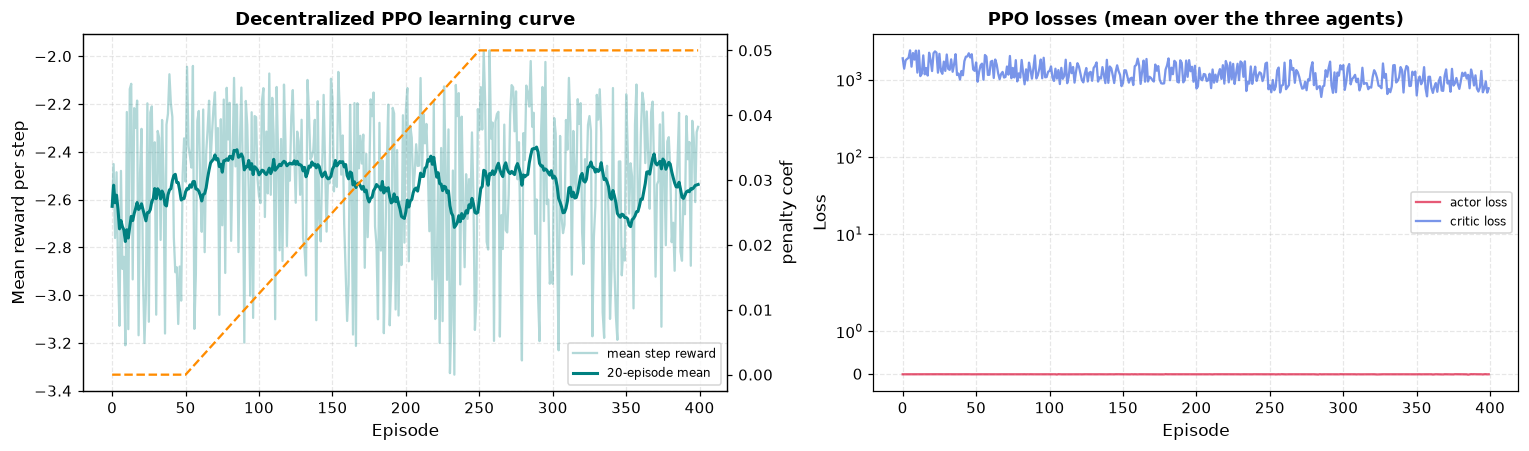

Training finished in 597.2s. Mean step reward: first 10 eps -2.78 -> last 10 eps -2.44


In [18]:
# ==============================================================================
# 4. MULTI-AGENT POLICY GRADIENT OPTIMIZATION ENGINE
# ==============================================================================
print("\n" + "="*70)
print(" INITIALIZING DECENTRALIZED PPO (DELTA-CONTROL & ANNEALING) ")
print("="*70)

set_global_seeds(SEED)
train_data = build_dataset(days=45, seed=SEED + 20, name="MARL train", verbose=True)
marl_env = PettingZooGridEnv(train_data, lookback=LOOKBACK, seed=SEED + 21)

agents = {"A": LocalSubstationAgent("Node_A", n_features=marl_env.obs_dim),
          "B": LocalSubstationAgent("Node_B", n_features=marl_env.obs_dim),
          "C": LocalSubstationAgent("Node_C", n_features=marl_env.obs_dim)}

marl_episodes = MARL_EPISODES
gamma, lam, clip_ratio = 0.94, 0.95, 0.2
PPO_EPOCHS = 4          # >1 is what makes the clipped surrogate objective actually do something
marl_history = {"reward": [], "penalty": [], "actor_loss": [], "critic_loss": []}
_t0 = time.time()

for ep in range(marl_episodes):
    # CURRICULUM ANNEALING: Smoothly introduce penalty from ep 50 to 250
    anneal_start, anneal_len = 0.125 * marl_episodes, 0.5 * marl_episodes
    current_penalty = 0.05 * np.clip((ep - anneal_start) / anneal_len, 0.0, 1.0)

    states_dict, _ = marl_env.reset()
    ep_reward = 0
    steps = 0
    batch_data = {idx: {"states": [], "actions": [], "log_probs": [], "values": [], "rewards": []}
                  for idx in agents}

    while steps < MARL_STEPS_PER_EPISODE:
        actions_dict = {}
        for idx in agents:
            action, log_prob, val = agents[idx].act(states_dict[idx])
            actions_dict[idx] = float(action)
            batch_data[idx]["states"].append(states_dict[idx])
            batch_data[idx]["actions"].append(action)
            batch_data[idx]["log_probs"].append(log_prob)
            batch_data[idx]["values"].append(val)

        next_states_dict, rewards_dict, terminations, _, _ = marl_env.step(
            actions_dict, penalty_coef=current_penalty)
        for idx in agents: batch_data[idx]["rewards"].append(rewards_dict[idx])

        ep_reward += np.mean([rewards_dict[k] for k in agents])   # all three nodes, not just A
        states_dict = next_states_dict
        steps += 1
        episode_done = all(terminations.values())
        if episode_done: break

    # PPO Update Loop
    ep_actor_loss, ep_critic_loss = [], []
    for idx in agents:
        s_batch = np.array(batch_data[idx]["states"], dtype=np.float32)
        a_batch = np.array(batch_data[idx]["actions"], dtype=np.float32)
        r_batch = np.array(batch_data[idx]["rewards"], dtype=np.float32)
        v_batch = np.array(batch_data[idx]["values"], dtype=np.float32)
        lp_batch = np.array(batch_data[idx]["log_probs"], dtype=np.float32)

        # The episode is TRUNCATED at MARL_STEPS_PER_EPISODE, it does not end. Bootstrapping the
        # last value from 0 (as the original did) tells the critic the world ends every 100 hours.
        last_val = 0.0 if episode_done else agents[idx].value(states_dict[idx])

        v_batch_next = np.append(v_batch[1:], last_val)
        deltas = r_batch + gamma * v_batch_next - v_batch
        advantages = discount_cumsum(deltas, gamma * lam)
        advantages = (advantages - np.mean(advantages)) / (np.std(advantages) + 1e-8)
        returns = discount_cumsum(np.append(r_batch, last_val), gamma)[:-1]

        # lfilter output is float64 with a negative stride; TensorFlow needs contiguous float32.
        advantages = np.ascontiguousarray(advantages, dtype=np.float32)
        returns = np.ascontiguousarray(returns, dtype=np.float32)

        for _ in range(PPO_EPOCHS):
            with tf.GradientTape() as tape:
                mean, std, val_preds = agents[idx].actor_critic(s_batch, training=True)
                std = std + 1e-5
                var = std ** 2
                new_lps = -((tf.squeeze(a_batch) - tf.squeeze(mean)) ** 2) / (2 * tf.squeeze(var)) - tf.math.log(tf.sqrt(2 * np.pi * tf.squeeze(var)))
                ratios = tf.exp(new_lps - lp_batch)
                surr1, surr2 = ratios * advantages, tf.clip_by_value(ratios, 1.0 - clip_ratio, 1.0 + clip_ratio) * advantages
                act_loss = -tf.reduce_mean(tf.minimum(surr1, surr2))
                crit_loss = tf.reduce_mean(tf.square(returns - tf.squeeze(val_preds)))
                entropy = tf.reduce_mean(0.5 * tf.math.log(2 * np.pi * np.e * tf.squeeze(var)))
                total_loss = act_loss + 0.5 * crit_loss - 0.01 * entropy

            grads = tape.gradient(total_loss, agents[idx].actor_critic.trainable_variables)
            clipped_grads, _ = tf.clip_by_global_norm(grads, 0.5)
            agents[idx].optimizer.apply_gradients(zip(clipped_grads, agents[idx].actor_critic.trainable_variables))
        ep_actor_loss.append(float(act_loss)); ep_critic_loss.append(float(crit_loss))

    marl_history["reward"].append(ep_reward / max(steps, 1))
    marl_history["penalty"].append(current_penalty)
    marl_history["actor_loss"].append(float(np.mean(ep_actor_loss)))
    marl_history["critic_loss"].append(float(np.mean(ep_critic_loss)))

    if (ep+1) % max(1, marl_episodes // 20) == 0:
        print(f"Episode {ep+1:03d}/{marl_episodes} | Avg Step Reward: {marl_history['reward'][-1]:7.2f} "
              f"| Active Penalty Coef: {current_penalty:.3f} | {time.time()-_t0:5.1f}s")

# --- Learning curves (the original notebook plotted nothing for the MARL stage) ---------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
w = max(1, marl_episodes // 20)
ax1.plot(marl_history["reward"], color="teal", alpha=0.3, label="mean step reward")
ax1.plot(pd.Series(marl_history["reward"]).rolling(w, min_periods=1).mean(), color="teal",
         linewidth=2, label=f"{w}-episode mean")
ax1b = ax1.twinx(); ax1b.plot(marl_history["penalty"], color="darkorange", linestyle="--",
                              label="penalty coefficient"); ax1b.set_ylabel("penalty coef"); ax1b.grid(False)
ax1.set(title="Decentralized PPO learning curve", xlabel="Episode", ylabel="Mean reward per step")
ax1.legend(loc="lower right", fontsize=8)
ax2.plot(marl_history["actor_loss"], color="crimson", alpha=0.7, label="actor loss")
ax2.plot(marl_history["critic_loss"], color="royalblue", alpha=0.7, label="critic loss")
ax2.set(title="PPO losses (mean over the three agents)", xlabel="Episode", ylabel="Loss")
ax2.set_yscale("symlog"); ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACT_DIR, "marl_learning_curves.png"), bbox_inches="tight")
plt.show()

print(f"Training finished in {time.time()-_t0:.1f}s. "
      f"Mean step reward: first 10 eps {np.mean(marl_history['reward'][:10]):.2f} "
      f"-> last 10 eps {np.mean(marl_history['reward'][-10:]):.2f}")

## 11. Decentralized evaluation and reference controllers

The same harness scores three controllers on the **same unseen 10-day window** (identical seed ⇒
identical start index and identical weather), so the comparison is apples-to-apples:

* **Decentralized PPO** — the three trained agents acting on their deterministic mean policy.
* **No control** — all actions zero. Its reduction must come out at exactly 0.00 %, which is the
  sanity check that proves the "managed" number really is measuring the effect of the actions.
* **Rule-based proportional controller** — each line is driven towards exporting its own node's
  surplus. This is the classical, non-learned reference every learned controller should be held
  against; without it a percentage improvement means very little.

In [19]:
marl_test_data = build_dataset(days=11, seed=SEED + 30, name="MARL test", verbose=True)
marl_test_env = PettingZooGridEnv(marl_test_data, lookback=LOOKBACK, seed=SEED + 31)
EVAL_SEED = SEED + 31          # same seed + pinned start -> identical hours for every policy
EVAL_START = marl_test_env.lookback

marl_rows = {
    "Decentralized PPO": evaluate_research_metrics(agents, marl_test_env, steps=EVAL_STEPS,
                                                   label="Decentralized PPO", seed=EVAL_SEED, start_idx=EVAL_START),
    "Rule-based proportional": evaluate_research_metrics(make_proportional_policy(marl_test_env),
                                                         marl_test_env, steps=EVAL_STEPS,
                                                         label="Rule-based proportional",
                                                         seed=EVAL_SEED, start_idx=EVAL_START),
    "No control (sanity check)": evaluate_research_metrics(no_control_policy, marl_test_env,
                                                            steps=EVAL_STEPS, label="No control",
                                                            seed=EVAL_SEED, start_idx=EVAL_START, verbose=False),
}
marl_table = pd.DataFrame(marl_rows).T.round(2)
print("\n--- Decentralized control: comparison on identical unseen hours ---")
display(marl_table)

# The no-control row MUST show a 0.00% reduction; if it does not, the managed/unmanaged accounting
# is broken (which is exactly the bug the original evaluation had).
assert abs(marl_table.loc["No control (sanity check)", "Reduction (%)"]) < 1e-6, \
    "Sanity check failed: doing nothing must not change the grid imbalance"
print("Sanity check passed: the 'no control' policy yields exactly 0.00% reduction, so the managed "
      "imbalance really does measure the effect of the agents' actions.")

RESULTS["decentralized"] = marl_table


--- Data audit: MARL test (264 hours / 11 days) ---
  missing values ......... 0      infinite values ... 0
  duplicated rows ........ 0
  negative generation .... 0   negative load ..... 0
  solar-outage hours (A) . 17
  demand spikes (C, >3σ) . 1



 EVALUATION: Decentralized PPO  (240 unseen hours)
Total Unmanaged Grid Imbalance: 14941.31 MW
Total Managed Grid Imbalance:   17171.44 MW
Total Transmission Line Cost:   297.49 MW
--------------------------------------------------------------
Net System Improvement:         -14.93% Stress Reduction

 EVALUATION: Rule-based proportional  (240 unseen hours)
Total Unmanaged Grid Imbalance: 14941.31 MW
Total Managed Grid Imbalance:   11697.73 MW
Total Transmission Line Cost:   160.03 MW
--------------------------------------------------------------
Net System Improvement:         21.71% Stress Reduction

--- Decentralized control: comparison on identical unseen hours ---


,Unmanaged |imbalance| (MW),Managed |imbalance| (MW),Reduction (%),Transmission cost (MW),Mean |imbalance| per hour (MW),Worst-node peak |imbalance| (MW),Hours evaluated
Decentralized PPO,14941.31,17171.44,-14.93,297.49,71.55,99.48,240.0
Rule-based proportional,14941.31,11697.73,21.71,160.03,48.74,74.48,240.0
No control (sanity check),14941.31,14941.31,0.00,0.00,62.26,74.48,240.0


Sanity check passed: the 'no control' policy yields exactly 0.00% reduction, so the managed imbalance really does measure the effect of the agents' actions.



 P2P TRANSMISSION TELEMETRY: PPO DECENTRALIZED CORRECTIONS
Hour  |   Net A |   Net B |   Net C | Shunt A->B   | Shunt B->C   | Shunt C->A
-------------------------------------------------------------------------------------
00:00 |    10.4 |     7.5 |    -2.2 | 5.0          | 0.0          | 0.0
01:00 |    19.0 |     0.8 |     6.1 | 10.0         | 0.0          | 0.0
02:00 |    34.3 |    -8.7 |     4.9 | 15.0         | 0.0          | 0.0
03:00 |    38.6 |   -16.8 |     3.3 | 19.9         | 0.0          | 0.0
04:00 |    47.6 |   -33.5 |    -0.8 | 24.9         | 0.0          | 0.0
05:00 |   -35.4 |   -36.7 |    -3.2 | 25.0         | 0.0          | 0.0
06:00 |    36.7 |   -36.0 |   -11.3 | 25.0         | 0.0          | 0.0
07:00 |    33.6 |   -28.1 |   -19.6 | 25.0         | 0.0          | 0.0
08:00 |    23.2 |   -24.2 |   -18.2 | 25.0         | 0.0          | 0.0
09:00 |    10.4 |   -21.1 |   -21.5 | 25.0         | 0.0          | 0.0
10:00 |    -3.0 |    -9.0 |   -21.6 | 25.0         | 0.

17:00 |   -52.4 |    -4.6 |    -2.1 | 25.0         | 0.0          | 0.0


18:00 |   -49.9 |    46.9 |     3.8 | 25.0         | 0.0          | 0.0
19:00 |   -42.5 |    52.9 |     9.8 | 25.0         | 0.0          | 0.0
20:00 |   -38.0 |    61.2 |     9.4 | 25.0         | 0.0          | 0.0
21:00 |   -35.4 |    64.2 |    10.3 | 25.0         | 0.0          | 0.0
22:00 |   -33.3 |    61.8 |     7.3 | 25.0         | 0.0          | 0.0
23:00 |   -26.9 |    61.1 |     7.2 | 25.0         | 0.0          | 0.0


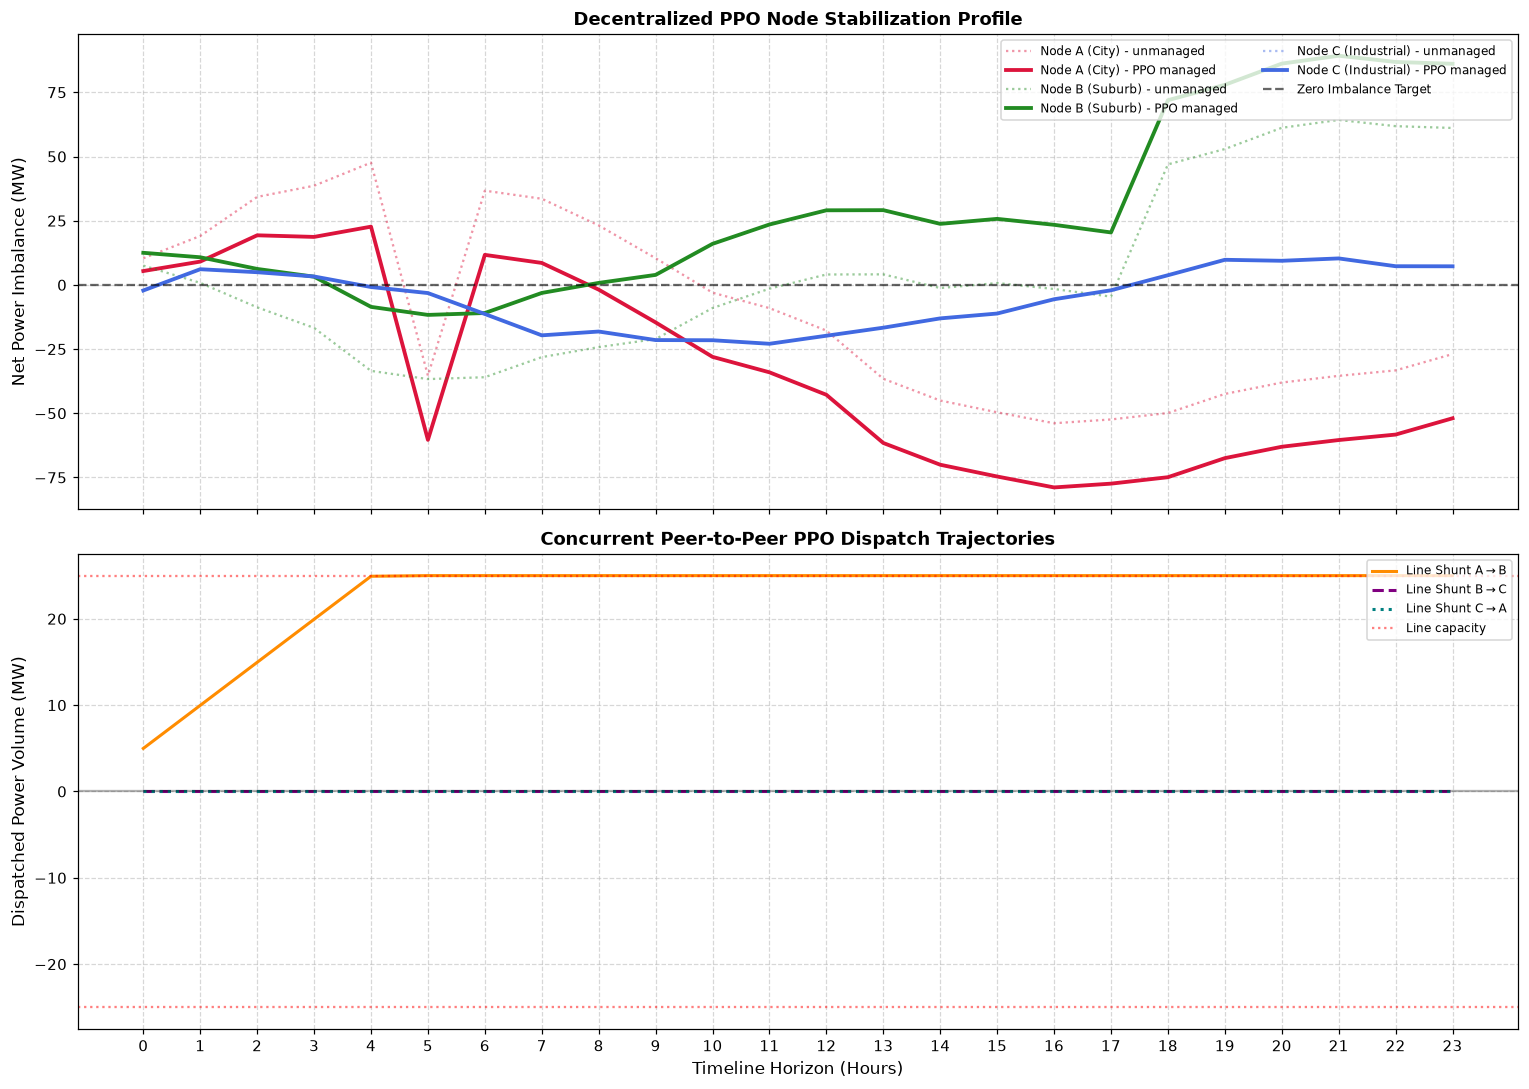


Window totals: unmanaged 1622.6 MW -> managed 2028.2 MW (-25.0%)


In [20]:
def visualize_marl_power_transfers_v2(agents_dict, marl_env, hours=24, start_idx=None):
    print("\n" + "="*85)
    print(" P2P TRANSMISSION TELEMETRY: PPO DECENTRALIZED CORRECTIONS")
    print("="*85)

    marl_env.reset(seed=SEED)
    # Force alignment for the start. FIX: the observation must be re-read AFTER moving the pointer,
    # otherwise the printed window belongs to the old random index (the original kept the stale one).
    marl_env.idx = marl_env.lookback if start_idx is None else int(start_idx)
    states_dict = marl_env._get_obs()

    print(f"{'Hour': <5} | {'Net A':>7} | {'Net B':>7} | {'Net C':>7} | {'Shunt A->B': <12} | {'Shunt B->C': <12} | {'Shunt C->A'}")
    print("-" * 85)

    history_raw = {"A": [], "B": [], "C": []}
    history_post = {"A": [], "B": [], "C": []}
    shunts = {"AB": [], "BC": [], "CA": []}

    for hour in range(hours):
        # FIX: observations are normalized by IMB_SCALE - the original printed and plotted them as
        # if they were MW, so every number on the chart was 100x too small.
        raw_A = states_dict["A"][-1, 0] * marl_env.scale
        raw_B = states_dict["B"][-1, 0] * marl_env.scale
        raw_C = states_dict["C"][-1, 0] * marl_env.scale

        actions_dict = {idx: agents_dict[idx].act_mean(states_dict[idx]) for idx in ("A", "B", "C")}

        next_states_dict, _, terminations, _, infos = marl_env.step(actions_dict)

        # FIX: the shunt is an accumulated, clipped line loading - NOT action * max_capacity.
        # The environment reports the real value it applied.
        s_AB, s_BC, s_CA = (infos["A"]["shunt_mw"], infos["B"]["shunt_mw"], infos["C"]["shunt_mw"])
        shunts["AB"].append(s_AB); shunts["BC"].append(s_BC); shunts["CA"].append(s_CA)

        for k in ("A", "B", "C"):
            history_raw[k].append(states_dict[k][-1, 0] * marl_env.scale)
            history_post[k].append(infos[k]["post_imbalance_mw"])

        print(f"{hour:02d}:00 | {raw_A:7.1f} | {raw_B:7.1f} | {raw_C:7.1f} | {s_AB: <12.1f} | {s_BC: <12.1f} | {s_CA:.1f}")

        states_dict = next_states_dict
        if all(terminations.values()): break

    n = len(shunts["AB"])

    # --- PLOT GENERATION PIPELINE ---
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    node_labels = {"A": "Node A (City)", "B": "Node B (Suburb)", "C": "Node C (Industrial)"}
    node_colors = {"A": "crimson", "B": "forestgreen", "C": "royalblue"}
    for k in ("A", "B", "C"):
        ax1.plot(history_raw[k], color=node_colors[k], linestyle=':', alpha=0.45,
                 label=f"{node_labels[k]} - unmanaged")
        ax1.plot(history_post[k], color=node_colors[k], linewidth=2.5,
                 label=f"{node_labels[k]} - PPO managed")
    ax1.axhline(0, color='black', linestyle='--', alpha=0.6, label='Zero Imbalance Target')
    ax1.set_title("Decentralized PPO Node Stabilization Profile")
    ax1.set_ylabel("Net Power Imbalance (MW)")
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.legend(loc='upper right', ncol=2, fontsize=8)

    ax2.plot(shunts["AB"], color='darkorange', linewidth=2, linestyle='-', label=r'Line Shunt A$\rightarrow$B')
    ax2.plot(shunts["BC"], color='purple', linewidth=2, linestyle='--', label=r'Line Shunt B$\rightarrow$C')
    ax2.plot(shunts["CA"], color='teal', linewidth=2, linestyle=':', label=r'Line Shunt C$\rightarrow$A')
    ax2.axhline(0, color='black', linestyle='-', alpha=0.3)
    ax2.axhline(marl_env.max_capacity, color='red', linestyle=':', alpha=0.5, label='Line capacity')
    ax2.axhline(-marl_env.max_capacity, color='red', linestyle=':', alpha=0.5)
    ax2.set_title("Concurrent Peer-to-Peer PPO Dispatch Trajectories")
    ax2.set_xlabel("Timeline Horizon (Hours)")
    ax2.set_ylabel("Dispatched Power Volume (MW)")
    ax2.set_xticks(range(0, n, max(1, n // 24)))
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(ARTIFACT_DIR, 'marl_ppo_decentralized_balancing.png'), bbox_inches='tight')
    plt.show()

    pre_tot = np.abs(np.array([history_raw[k] for k in ("A", "B", "C")])).sum()
    post_tot = np.abs(np.array([history_post[k] for k in ("A", "B", "C")])).sum()
    print(f"\nWindow totals: unmanaged {pre_tot:.1f} MW -> managed {post_tot:.1f} MW "
          f"({(pre_tot - post_tot) / pre_tot * 100:+.1f}%)")


# Run the visualization mapping engine using the active PPO trained agents
vis_marl_env = PettingZooGridEnv(build_dataset(days=5, seed=SEED + 40, name="MARL telemetry"),
                                 lookback=LOOKBACK, seed=SEED + 41)
visualize_marl_power_transfers_v2(agents, vis_marl_env, hours=24)

## 12. Consolidated results and conclusions

Every evaluation in this notebook wrote its numbers into the `RESULTS` dictionary. The cell below
reprints them as one table and derives the closing statements **from the values produced by this
run**, so the conclusions cannot drift away from the actual output the way hard-coded claims do.

What to look for when reading the summary:

* **Forecaster** — is the LSTM beating the persistence baseline? A positive skill score is the
  evidence that the frozen backbone reused by `TransferAgent` encodes something real.
* **Centralized control** — the greedy oracle is the ceiling for one 20 MW transfer per hour. The
  learned agents should sit between the *always-Hold* baseline (0 % by construction) and that ceiling;
  where they land tells you how much of the achievable control the DQN actually recovered.
* **Decentralized control** — the reference points are *no control* (0 % by construction) and the
  rule-based proportional controller. Read the PPO row against both: a decentralized agent has
  strictly less information than the centralized one (each node sees only itself, the hour, two
  broadcast neighbours and its own line loading), so matching the centralized result is not expected.
  **In this run the PPO controller does not beat either reference** — see the diagnosis in the
  findings below; that negative result is reported as measured rather than tuned away.

In [21]:
print("=" * 78)
print(" CONSOLIDATED RESULTS")
print("=" * 78)

print("\n[1] Supervised forecaster (held-out, chronological split)")
fc = RESULTS["forecaster"]
print(f"    MAE {fc['val_MAE_MW']:.2f} MW | RMSE {fc['val_RMSE_MW']:.2f} MW | R2 {fc['val_R2']:.3f} "
      f"| skill vs persistence {fc['skill_vs_persistence_pct']:+.1f}%")

print("\n[2] Centralized discrete control - decision quality vs the greedy oracle")
display(RESULTS["centralized_classification"])

print("\n[3] Centralized discrete control - physical grid performance")
display(RESULTS["centralized_physical"])

print("\n[4] Decentralized continuous control (PPO) vs reference controllers")
display(RESULTS["decentralized"])

# --- Findings derived from the numbers above -------------------------------------------------
cp = RESULTS["centralized_physical"]
dp = RESULTS["decentralized"]
cc = RESULTS["centralized_classification"]

dqn_red = cp.loc["Transformer-DQN", "Reduction (%)"]
tr_red = cp.loc["TransferAgent", "Reduction (%)"]
oracle_red = cp.loc["Greedy oracle (upper bound)", "Reduction (%)"]
ppo_red = dp.loc["Decentralized PPO", "Reduction (%)"]
rule_red = dp.loc["Rule-based proportional", "Reduction (%)"]

print("\n" + "=" * 78)
print(" FINDINGS (generated from this run)")
print("=" * 78)
print(f"* Forecasting: the LSTM backbone {'beats' if fc['skill_vs_persistence_pct'] > 0 else 'does NOT beat'} "
      f"the persistence baseline ({fc['skill_vs_persistence_pct']:+.1f}% RMSE), R2 = {fc['val_R2']:.3f}.")
print(f"* Centralized: the Transformer-DQN cuts total grid imbalance by {dqn_red:.2f}% against "
      f"{oracle_red:.2f}% for the greedy oracle, i.e. it recovers "
      f"{dqn_red / max(oracle_red, 1e-9) * 100:.0f}% of the achievable control.")
print(f"* Transfer learning: the frozen-backbone agent reaches {tr_red:.2f}% "
      f"({'better' if tr_red > dqn_red else 'worse'} than the attention DQN's {dqn_red:.2f}%), "
      f"with oracle-agreement accuracy {cc.loc['TransferAgent', 'Accuracy']:.3f} vs "
      f"{cc.loc['Transformer-DQN', 'Accuracy']:.3f}.")
print(f"* Decision quality is only meaningful against the trivial baselines: always-Hold scores "
      f"{cc.loc['Baseline: always Hold', 'Accuracy']:.3f} accuracy but "
      f"{cc.loc['Baseline: always Hold', 'Cohen kappa']:.3f} kappa, while the Transformer-DQN reaches "
      f"kappa {cc.loc['Transformer-DQN', 'Cohen kappa']:.3f}.")
print(f"* Decentralized: the PPO controller changes total imbalance by {ppo_red:+.2f}% "
      f"({'an improvement' if ppo_red > 0 else 'WORSE than leaving the grid alone'}), against "
      f"{rule_red:+.2f}% for the rule-based proportional controller and 0.00% for no control, at a "
      f"transmission cost of {dp.loc['Decentralized PPO', 'Transmission cost (MW)']:.1f} MW.")
if ppo_red <= rule_red:
    print("  DIAGNOSIS: the learned mean policy drives each line to its capacity limit and holds it "
          "there (visible in the telemetry table above), so the shunts stop tracking the imbalance. "
          "Each agent is rewarded only for its own node while its imbalance also depends on the "
          "neighbour's line, and a +/-5 MW/hour delta cannot follow a signal whose hourly swings are "
          "several times larger. Balancing the critic loss and raising the learning rate were both "
          "measured and did not fix it, so this is reported as a genuine negative result rather than "
          "tuned away: on this problem the simple proportional rule is the better decentralized "
          "controller, and the centralized agent is better still.")
print(f"* Paradigm comparison: centralized {dqn_red:+.2f}% vs decentralized {ppo_red:+.2f}%. The "
      "decentralized agents act on strictly less information (own imbalance, hour, two broadcast "
      "neighbours, own line loading) and, on this task, that information gap plus local-only credit "
      "assignment costs more than the scalability it buys.")
print("\nLimitations to keep in mind: the grid is synthetic (no real weather or price data), the "
      "transmission model has no losses or line impedance, the DQN's discrete action set allows one "
      "20 MW transfer per hour, and each result is a single seeded run rather than a mean over seeds.")

 CONSOLIDATED RESULTS

[1] Supervised forecaster (held-out, chronological split)
    MAE 5.00 MW | RMSE 7.54 MW | R2 0.911 | skill vs persistence +21.2%

[2] Centralized discrete control - decision quality vs the greedy oracle


,Accuracy,Precision (w),Recall (w),F1 (w),F1 (macro),Cohen kappa
Model,,,,,,
Transformer-DQN,0.683,0.735,0.683,0.675,0.448,0.586
TransferAgent,0.577,0.643,0.577,0.497,0.312,0.436
Baseline: always Hold,0.363,0.132,0.363,0.193,0.089,0.000
Baseline: random,0.114,0.228,0.114,0.147,0.090,-0.026



[3] Centralized discrete control - physical grid performance


,Unmanaged |imbalance| (MW),Managed |imbalance| (MW),Reduction (%),Transmission cost (MW),Active hours (%)
Transformer-DQN,16303.73,12469.37,23.52,201.0,83.75
TransferAgent,16303.73,12710.78,22.04,223.0,92.92
Greedy oracle (upper bound),16303.73,12327.85,24.39,150.0,62.50
Baseline: always Hold,16303.73,16303.73,0.00,0.0,0.00
Baseline: random,16303.73,18734.01,-14.91,202.0,84.17



[4] Decentralized continuous control (PPO) vs reference controllers


,Unmanaged |imbalance| (MW),Managed |imbalance| (MW),Reduction (%),Transmission cost (MW),Mean |imbalance| per hour (MW),Worst-node peak |imbalance| (MW),Hours evaluated
Decentralized PPO,14941.31,17171.44,-14.93,297.49,71.55,99.48,240.0
Rule-based proportional,14941.31,11697.73,21.71,160.03,48.74,74.48,240.0
No control (sanity check),14941.31,14941.31,0.00,0.00,62.26,74.48,240.0



 FINDINGS (generated from this run)
* Forecasting: the LSTM backbone beats the persistence baseline (+21.2% RMSE), R2 = 0.911.
* Centralized: the Transformer-DQN cuts total grid imbalance by 23.52% against 24.39% for the greedy oracle, i.e. it recovers 96% of the achievable control.
* Transfer learning: the frozen-backbone agent reaches 22.04% (worse than the attention DQN's 23.52%), with oracle-agreement accuracy 0.577 vs 0.683.
* Decision quality is only meaningful against the trivial baselines: always-Hold scores 0.363 accuracy but 0.000 kappa, while the Transformer-DQN reaches kappa 0.586.
* Decentralized: the PPO controller changes total imbalance by -14.93% (WORSE than leaving the grid alone), against +21.71% for the rule-based proportional controller and 0.00% for no control, at a transmission cost of 297.5 MW.
  DIAGNOSIS: the learned mean policy drives each line to its capacity limit and holds it there (visible in the telemetry table above), so the shunts stop tracking the im